#  Series temporales. Modelos de Suavizado exponencial y ARIMA

En este documento exploramos distintos modelos de suavizado y ARIMA para series univariantes. Este código servirá para los días 5 y 6 ya que resulta cómodo e ilustrativo aplicar todos los métodos a cada conjunto de datos y poder comparar los resultados.

La idea será buscar los mejores modelos para la predicción de series temporales para los datos que nos lleguen.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Series temporales I. Suavizado

En esta primera sesión vamos a explorar los métodos de inspección descriptiva de una serie temporal y, posteriormente, los primeros modelos predictivos basados en suavizado exponencial.

El esquema de trabajo será:

1. Leer valores de la serie y convertir a formato legible por python
2. Representar la serie para intuir componentes presentes
3. Descomposición de la serie y contraste de estacionariedad
4. Creación de partición en ventanas training/test
5. Aplicación de modelos de suavizado y evaluación de ajuste
6. Aplicación de modelos Arima y evaluación de ajuste

Con esto tendremos una primera aproximación para la predicción de datos a futuro en una serie temporal univariante.


In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt


In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# pip install r2py
from rpy2.robjects.packages import importr, data

datasets = importr('datasets')
AirPassengers = pd.Series(data(datasets).fetch('AirPassengers')['AirPassengers'])
AirPassengers


,0
0,112.0
1,118.0
2,132.0
3,129.0
4,121.0
...,...
139,606.0
140,508.0
141,461.0
142,390.0


Asignamos manualmente la fecha de inicio a fin en intervalos mensuales ya que esta lectura no devuelve las fechas correctamente.. (tenemos de todas formas el csv en la carpeta por si lo necesitáramos). Con date_range generamos las fechas.



In [ ]:
fechas = pd.date_range('1949-01-01','1960-12-01',
               freq='MS').strftime("%Y-%m").tolist()
fechas = pd.Series(fechas)
fechas

,0
0,1949-01
1,1949-02
2,1949-03
3,1949-04
4,1949-05
...,...
139,1960-08
140,1960-09
141,1960-10
142,1960-11


Unimos las fechas a los valores de la serie.



In [ ]:
# Unir en un data
Air_R = pd.concat([fechas,AirPassengers], axis=1)
Air_R.columns = ['Month','Passengers']
Air_R.head()

,Month,Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


Check!

**Nota**: Esto solo funcionará si sois usuarias de R, es decir, tenéis instalado el software R en vuestro pc. De lo contrario obtendréis un error! Siempre podéis comentar estas líneas, realmente tenemos el archivo en csv y es más cómodo.

La lectura para gente no usuaria de R sería la siguiente.


In [ ]:
# Lo leemos desde el csv que desde R en el propio R colapsa el espacio-tiempo jeje
# Air = pd.read_csv('AirPassengers.csv')
# Air.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       144 non-null    object
 1   Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [ ]:
Air = Air_R

Convertimos a serie temporal para que python entienda con una simple asignación de la variable de fecha 'Month' en formato datetime por si acaso.



In [ ]:
# Convertir en serie temporal
Air.set_index(['Month'],inplace=True)
Air.index=pd.to_datetime(Air.index)


A ver cuál es el aspecto..



In [ ]:
Air



,Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
...,...
1960-08-01,606.0
1960-09-01,508.0
1960-10-01,461.0


Ya tenemos la serie preparada para analizar. En primer luegar haremos un estudio descriptivo, pintar, descomponer, entender las componentes y tal vez echar un vistazo a los correlogramas y tests de estacionariedad para los residuos de la descomposición "inocente" con la simple extracción de componentes.

## Estudio descriptivo

Aquí opción gráfica para que los plot() salgan grandes.


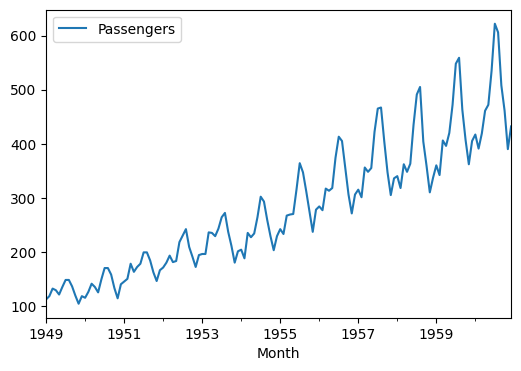

In [ ]:
plt.rcParams["figure.figsize"] = (6,4)
Air.plot()
plt.show()


Podemos definir una función que calcule el test de Dickey Fuller para la estacionariedad de la serie. De esta forma, en cualquier momento, introduciendo el vector de valores de la serie, obtendremos el contraste de hipótesis.

H0: La serie NO es estacionaria

H1: La serie es estacionaria

Por tanto, nos interesará que el contraste de hipótesis sea rechazado (p-valor < 0.05).


In [ ]:
from statsmodels.tsa.stattools import adfuller

def test_stationarity(timeseries):

    #Perform Dickey-Fuller test:
    print('Results of Dickey-Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC', regression ='ct')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput)


Probamos con la serie al natural.



In [ ]:
test_stationarity(Air)



Results of Dickey-Fuller Test:
Test Statistic                  -2.100782
p-value                          0.545659
#Lags Used                      13.000000
Number of Observations Used    130.000000
Critical Value (1%)             -4.030152
Critical Value (5%)             -3.444818
Critical Value (10%)            -3.147182
dtype: float64


### Descomposición de la serie

En base a la descomposición descriptiva por medias móviles, se extraen las componentes de tendencia y estacionalidad.

**Descomposición aditiva**


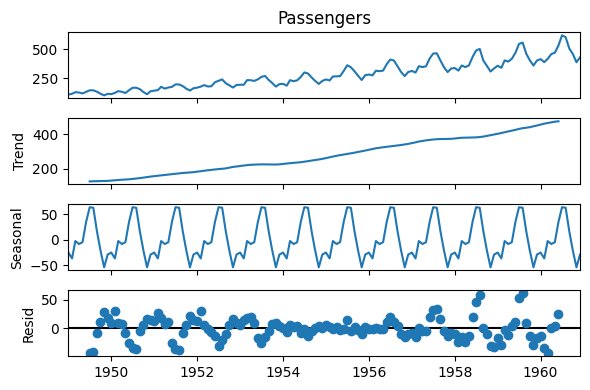

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Aplicar descomposición aditiva
Air_desc_Ad = seasonal_decompose(Air['Passengers'], model='additive',period=12)
Air_desc_Ad.plot()
plt.show()


In [ ]:
Air_desc_Ad.resid.head(30)

,resid
Month,
1949-01-01,NaN
1949-02-01,NaN
1949-03-01,NaN
1949-04-01,NaN
1949-05-01,NaN
1949-06-01,NaN
1949-07-01,-42.622475
1949-08-01,-42.073232
1949-09-01,-8.478535


Evaluamos estacionariedad de los residuos de la descomposición aditiva. Aquí, debido a que la tendencia se calcula por medias móviles, los primeros y últimos valores de la serie son NA, no se calculan. Simplemente saber esto y tener en cuenta solamente los residuos válidos.



In [ ]:
test_stationarity(Air_desc_Ad.resid.dropna())



Results of Dickey-Fuller Test:
Test Statistic                  -5.279797
p-value                          0.000062
#Lags Used                      13.000000
Number of Observations Used    118.000000
Critical Value (1%)             -4.037614
Critical Value (5%)             -3.448373
Critical Value (10%)            -3.149257
dtype: float64


**Descomposición multiplicativa**



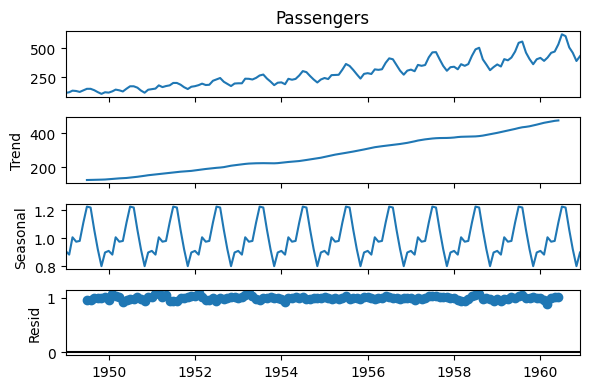

In [ ]:
# Aplicar descomposición aditiva
Air_desc_Mul = seasonal_decompose(Air['Passengers'], model='multiplicative')
Air_desc_Mul.plot()
plt.show()


Evaluamos estacionariedad de los residuos de la descomposición Multiplicativa.



In [ ]:
test_stationarity(Air_desc_Mul.resid.dropna())



Results of Dickey-Fuller Test:
Test Statistic                  -6.057240
p-value                          0.000002
#Lags Used                       9.000000
Number of Observations Used    122.000000
Critical Value (1%)             -4.034960
Critical Value (5%)             -3.447109
Critical Value (10%)            -3.148519
dtype: float64


In [ ]:
def seasonal_plot(df, season='year', index='month', column=None):
    """Makes a seasonal plot of one column of the input dataframe. Considers the first columns by default.

    Arguments:

    - df (Pandas DataFrame): DataFrame indexed by Datetime (see `parse_dates` parameter when reading a CSV);
    - season (string): the season that you want to considering when doing the plot, e.g., year, month, etc.;
    - index (string): corresponds to the X axis of the plot. You should choose based on the index period that you're using;
    - column (string, optional): the DataFrame column to consider. Picks the first one by default.
    """
    if column == None:
        column = df.columns[0]

    piv_index = getattr(df.index, index)
    piv_season = getattr(df.index, season)

    piv = pd.pivot_table(df, index=piv_index, columns=piv_season, values=[column])
    piv.plot(figsize=(12,8))


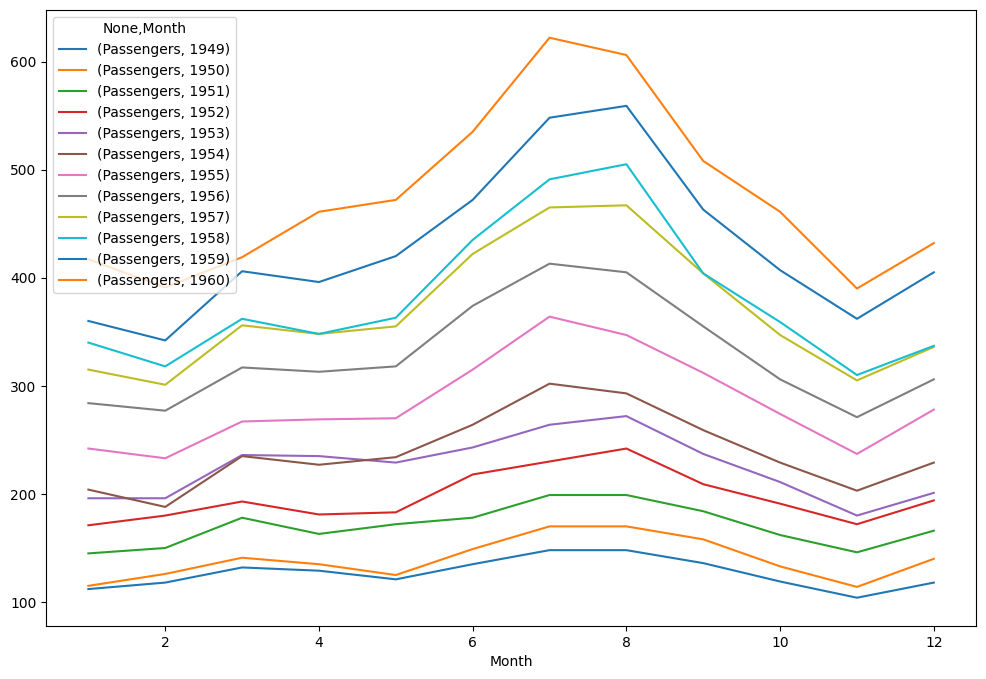

In [ ]:
seasonal_plot(Air)
plt.show()


### Hacia la estacionariedad

En esta sección vamos a extraer las componentes identificadas para generar una serie residual y comprobar si es estacionaria una vez eliminados los efectos típicos de las series temporales.

El esquema es:

1. Estabilización de la varianza. Transformación Logaritmica
2. Diferenciación regular
3. Diferenciación estacional

Con la serie resultante, comprobaremos estacionariedad y será con la que podemos valorar autocorrelaciones simples y parciales para proponer órdenes ARIMA tentativos par la serie.

#### Estabilización de la varianza. Transformación Logaritmica


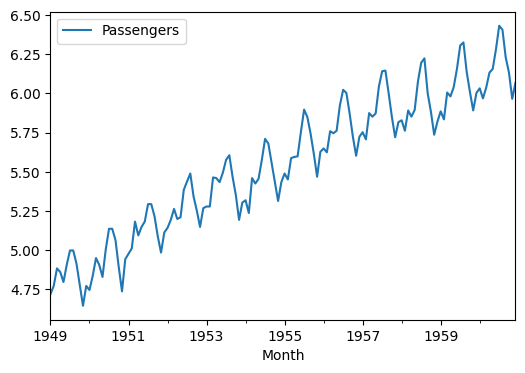

In [ ]:
AirLog = np.log(Air)
AirLog.plot()
plt.show()


#### Diferenciación regular



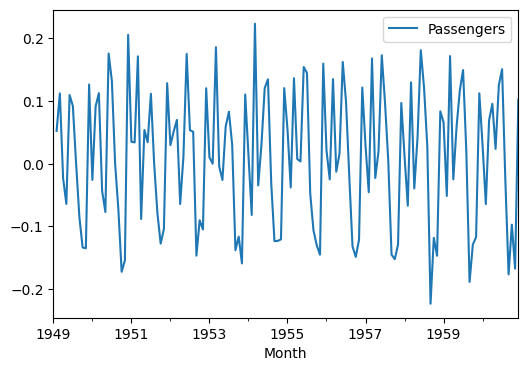

In [ ]:
AirLog_diff_1 = AirLog.diff(periods=1)
AirLog_diff_1.plot()
plt.show()


#### Diferenciación estacional



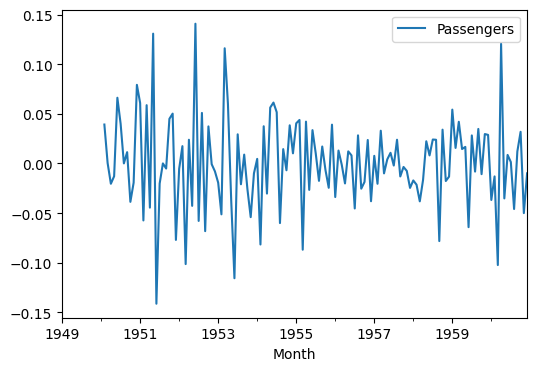

In [ ]:
AirLog_diff_1_12 = AirLog_diff_1.diff(periods=12)
AirLog_diff_1_12.plot()
plt.show()


#### Comprobación de estacionariedad



In [ ]:
test_stationarity(AirLog_diff_1_12.dropna(inplace=False))



Results of Dickey-Fuller Test:
Test Statistic                  -4.413001
p-value                          0.002087
#Lags Used                      12.000000
Number of Observations Used    118.000000
Critical Value (1%)             -4.037614
Critical Value (5%)             -3.448373
Critical Value (10%)            -3.149257
dtype: float64


#### Autocorrelaciones

Idea filosófica. Se recrean los estados t, t-1, t-2... de la serie como variables aleatorias que podemos relacionar como si fueran distintas columnas de nuestro dataset clásico de regresiones. Las autocorrelaciones son, por tanto, las correlaciones naturales entre estas variables! Fácil!

In [ ]:
# Recreación de los estados de la serie temporal
s=Air
df_lag=pd.concat([s, s.shift(), s.shift(2)], axis=1)
df_lag

,Passengers,Passengers,Passengers
Month,,,
1949-01-01,112.0,NaN,NaN
1949-02-01,118.0,112.0,NaN
1949-03-01,132.0,118.0,112.0
1949-04-01,129.0,132.0,118.0
1949-05-01,121.0,129.0,132.0
...,...,...,...
1960-08-01,606.0,622.0,535.0
1960-09-01,508.0,606.0,622.0
1960-10-01,461.0,508.0,606.0


In [ ]:
df_lag.columns= ['Pass','Pass_lag1','Pass_lag2']
df_lag.corr()

,Pass,Pass_lag1,Pass_lag2
Pass,1.000000,0.960195,0.895675
Pass_lag1,0.960195,1.000000,0.960249
Pass_lag2,0.895675,0.960249,1.000000


De esta forma se calculan las autocorrelaciones para el acf. La idea es la misma que en nuestros datasets clásicos de regresión, donde los predictores son la serie en distintos retardos.

In [ ]:
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


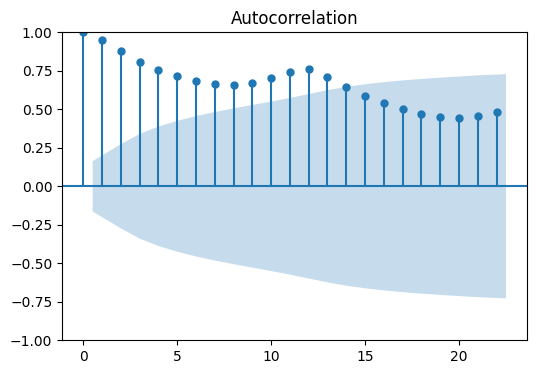

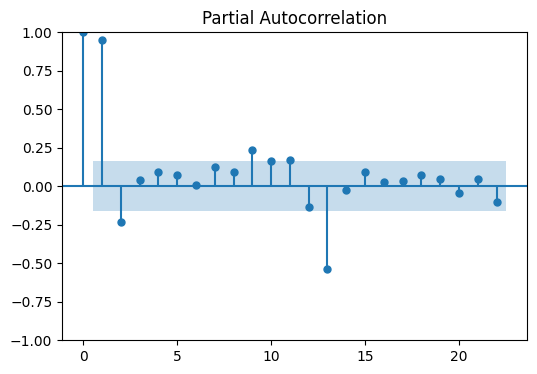

In [ ]:
plot_acf(Air)#,bartlett_confint=False)#.dropna(inplace=False))
plot_pacf(Air)
plt.show()


Las correlaciones parciales descuentan el efecto de los retardos intermedios y, para ello, correlacionan no Xt y Xt-2 sino ut y ut-2 que son los residuos de las regresiones de $$X_{t} = f(X_{t-1}) + u_{t}$$ y $$X_{t-2} = f(X_{t-1}) + u_{t-2}$$
Es decir, la parte de las variables afectadas que no es explicada por la variable intermedia. Se descuenta, por ello el efecto de este retardo intemedio entre los dos instantes a correlacionar.

In [ ]:
# Calculo aproximado manual de las correlaciones parciales. Idea filosófica.
from statsmodels.formula.api import ols
mod1=ols('Pass~Pass_lag1+Pass_lag2',df_lag).fit()
print(mod1.summary())
u1=mod1.resid
mod2=ols('Pass_lag2~Pass_lag1',df_lag).fit()
u2=mod2.resid
df_pacf=pd.concat([u1, u2], axis=1)
df_pacf.corr().round(2)

                            OLS Regression Results                            
Dep. Variable:                   Pass   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.928
Method:                 Least Squares   F-statistic:                     916.2
Date:                Sat, 13 Dec 2025   Prob (F-statistic):           8.97e-81
Time:                        09:54:27   Log-Likelihood:                -691.54
No. Observations:                 142   AIC:                             1389.
Df Residuals:                     139   BIC:                             1398.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     16.4821      6.884      2.394      0.0

,0,1
0,1.0,-0.0
1,-0.0,1.0


Probamos ahora a reproducir los estados de la serie diferenciada en lo regular.

In [ ]:
s_diff1 = AirLog_diff_1.dropna(inplace=False)
pd.concat([s_diff1, s_diff1.shift(1), s_diff1.shift(2)], axis=1).corr()

,Passengers,Passengers,Passengers
Passengers,1.000000,0.200388,-0.122039
Passengers,0.200388,1.000000,0.213323
Passengers,-0.122039,0.213323,1.000000


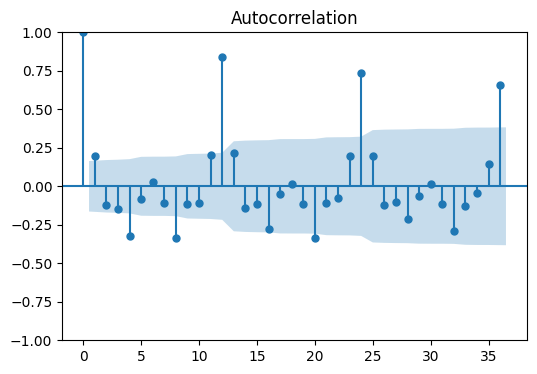

In [ ]:
plot_acf(AirLog_diff_1.dropna(inplace=False),lags=36)
plt.show()


In [ ]:
AirLog_diff_1_12

,Passengers
Month,
1949-01-01,NaN
1949-02-01,NaN
1949-03-01,NaN
1949-04-01,NaN
1949-05-01,NaN
...,...
1960-08-01,-0.045934
1960-09-01,0.012024
1960-10-01,0.031830


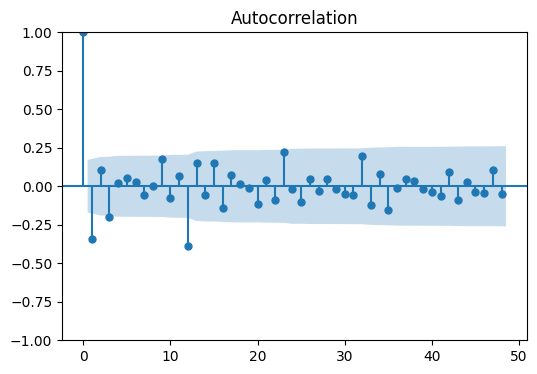

In [ ]:
plot_acf(AirLog_diff_1_12.dropna(inplace=False), lags=48)
plt.show()


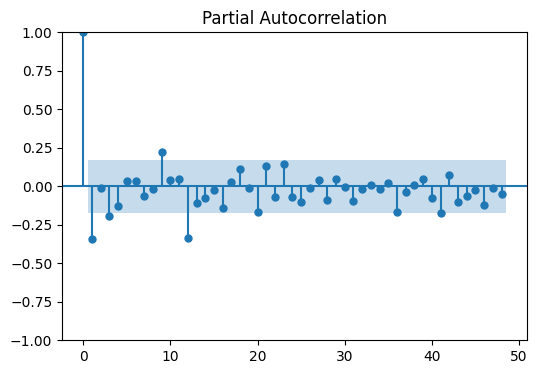

In [ ]:
plot_pacf(AirLog_diff_1_12.dropna(inplace=False), lags=48,method='ywm')
plt.show()

In [ ]:
Arima(0,1,1)(0,1,1)
Arima(1,1,1)(0,1,1)
Arima(2,1,8)(1,1,1)
Arima(1,1,0)(1,1,0)

In [ ]:
# Tets Ljung-box
sm.stats.acorr_ljungbox(AirLog_diff_1_12.dropna(inplace=False), lags=12, return_df=True)


,lb_stat,lb_pvalue
1,15.595655,7.843461e-05
2,17.086040,1.949008e-04
3,22.647794,4.781777e-05
4,22.710382,1.446614e-04
5,23.138684,3.175679e-04
6,23.270941,7.106307e-04
7,23.704967,1.283650e-03
8,23.705049,2.567712e-03
9,28.147330,9.012662e-04
10,28.986885,1.252151e-03


In [ ]:
sm.stats.acorr_ljungbox(Air, lags=12, return_df=True)



,lb_stat,lb_pvalue
1,132.141539,1.393231e-30
2,245.646160,4.556318e-54
3,342.674826,5.751088e-74
4,427.738684,2.817731e-91
5,504.796570,7.360195e-107
6,575.601854,4.264008e-121
7,643.038593,1.305463e-134
8,709.484498,6.496271e-148
9,779.591231,5.249370e-162
10,857.068639,1.100789e-177


## Modelos de suavizado

Exploramos ahora los distintos métodos de suavizado estudiados sobre la serie de pasajeros de avión. Antes de nada, tomamos las ventanas de training y test para ajuste y evaluación del modelo, respectivamente.


In [ ]:
import statsmodels.tsa.holtwinters as ets
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# Generamos la serie logaritmica
AirLog = Air.copy()
AirLog['Passengers'] = np.log(AirLog['Passengers'])
AirLog


Air_tr = AirLog[:'1958-12-01']
Air_tst = AirLog['1959-01-01':]
Air_tst

,Passengers
Month,
1959-01-01,5.886104
1959-02-01,5.834811
1959-03-01,6.006353
1959-04-01,5.981414
1959-05-01,6.040255
1959-06-01,6.156979
1959-07-01,6.306275
1959-08-01,6.326149
1959-09-01,6.137727


Definimos aquí una función para evaluar un modelo (será válido para modelos de suavizado y arima de statsmodels pero no para auto_arima...distintos valores de salida y ajustaremos luego la función para ello)



In [ ]:
#forecast_accuracy(fc, test.values)

# Función para evaluar modelo
def eval_model(model,tr,tst,name='Model',lags=12,serie='serie'):
    lb = np.mean(sm.stats.acorr_ljungbox(model.resid, lags=lags, return_df=True).lb_pvalue)
    pred = model.forecast(steps=len(tst))
    fig1, ax = plt.subplots()
    ax.plot(tr, label='training')
    ax.plot(tst, label='test')
    ax.plot(pred, label='prediction')
    plt.legend(loc='upper left')
    tit = name + ":  LjungBox p-value --> " + str(lb) + "\n MAPE: " + str(round(mean_absolute_percentage_error(tst, pred)*100,2)) + "%"
    plt.title(tit)
    plt.ylabel(serie)
    plt.xlabel('Date')
    plt.show()
    print(lb)



#### Suavizado Simple

Suavizado simple, ya sabemos que no va a ajustar bien pues es para series sin tendencia y estacionalidad. Solo por ver como ajustarlo en caso de necesidad. Esperamos predicciones constantes para la ventana de test.


In [ ]:
ses = ets.SimpleExpSmoothing(Air_tr).fit()

print(ses.summary())

                       SimpleExpSmoothing Model Results                       
Dep. Variable:             Passengers   No. Observations:                  120
Model:             SimpleExpSmoothing   SSE                              1.332
Optimized:                       True   AIC                           -536.073
Trend:                           None   BIC                           -530.498
Seasonal:                        None   AICC                          -535.725
Seasonal Periods:                None   Date:                 Fri, 12 Dec 2025
Box-Cox:                        False   Time:                         19:04:03
Box-Cox Coeff.:                  None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            1.0000000                alpha                 True
initial_level              4.7184989                

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Evaluación del modelo SES.



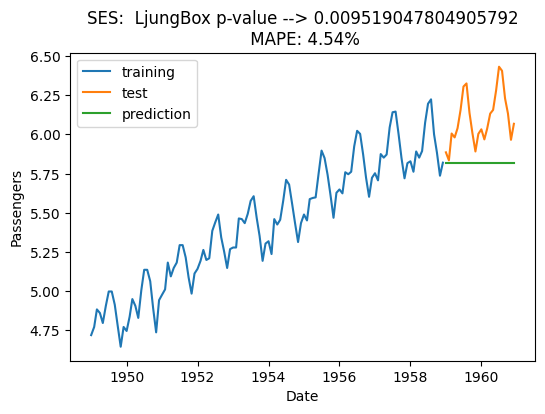

0.009519047804905792


In [ ]:
# Evaluar SES
eval_model(ses,Air_tr,Air_tst,'SES',serie='Passengers')


#### Suavizado doble de Holt

Suavizado doble de Holt, con pendiente pero sin componente estacional. Esperamos una recta con pendiente como predicción.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                              Holt Model Results                              
Dep. Variable:             Passengers   No. Observations:                  120
Model:                           Holt   SSE                              1.386
Optimized:                       True   AIC                           -527.298
Trend:                       Additive   BIC                           -516.148
Seasonal:                        None   AICC                          -526.555
Seasonal Periods:                None   Date:                 Fri, 12 Dec 2025
Box-Cox:                        False   Time:                         19:07:39
Box-Cox Coeff.:                  None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            1.0000000                alpha                 True
smoothing_trend            0.0273598                

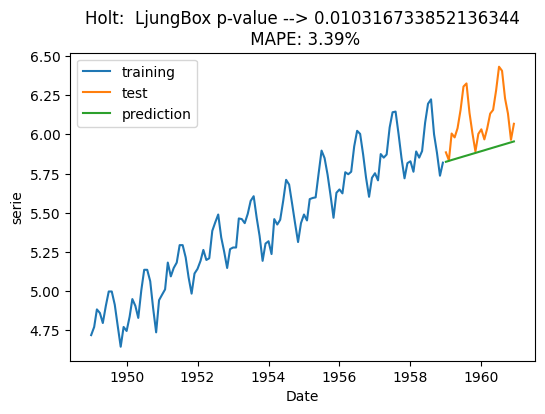

0.010316733852136344


In [ ]:
# Suavizado de Holt
holt = ets.Holt(Air_tr).fit()
print(holt.summary())

eval_model(holt,Air_tr,Air_tst,'Holt')


#### Suavizado de Holt Winters Aditivo

Ahora si, vamos a los métodos que podrían funcionar sobre esta serie. En primer lugar, Holt Winters aditivo. Con el aspecto de la serie y la clara heterocedasticidad, no parece que sea la mejor opción...pero probad con el logaritmo veréis que cambio.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                       ExponentialSmoothing Model Results                       
Dep. Variable:               Passengers   No. Observations:                  120
Model:             ExponentialSmoothing   SSE                          16033.603
Optimized:                         True   AIC                            619.394
Trend:                         Additive   BIC                            663.994
Seasonal:                      Additive   AICC                           626.166
Seasonal Periods:                    12   Date:                 Fri, 12 Dec 2025
Box-Cox:                          False   Time:                         19:13:20
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.2367490                alpha                 True
smoothing_trend          

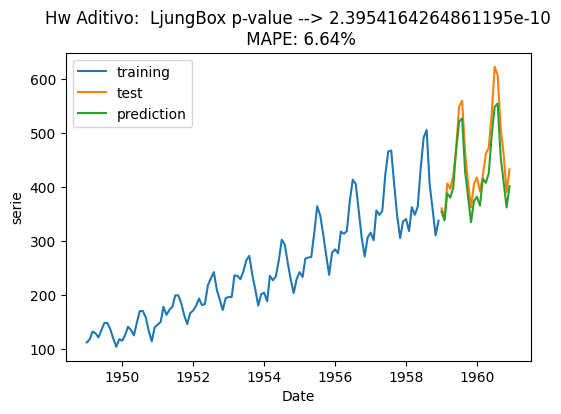

2.3954164264861195e-10


In [ ]:
hw_add = ets.ExponentialSmoothing(Air_tr,trend='add', damped_trend=False, seasonal='add').fit()
print(hw_add.summary())

eval_model(hw_add,Air_tr,Air_tst,'Hw Aditivo')


#### Suavizado de Holt Winters Multiplicativo

Suavizado multiplicativo para captar la componente estacional no constante con el tiempo.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                       ExponentialSmoothing Model Results                       
Dep. Variable:               Passengers   No. Observations:                  120
Model:             ExponentialSmoothing   SSE                          10764.240
Optimized:                         True   AIC                            571.579
Trend:                         Additive   BIC                            616.179
Seasonal:                Multiplicative   AICC                           578.351
Seasonal Periods:                    12   Date:                 Fri, 12 Dec 2025
Box-Cox:                          False   Time:                         19:14:01
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.3642177                alpha                 True
smoothing_trend          

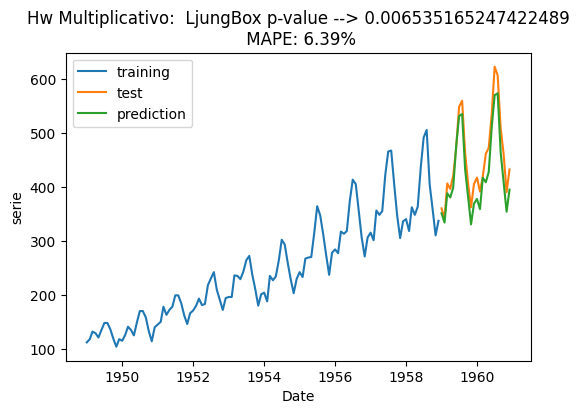

0.006535165247422489


In [ ]:
hw_mul = ets.ExponentialSmoothing(Air_tr,trend='add', damped_trend=False, seasonal='mul').fit()
print(hw_mul.summary())

eval_model(hw_mul,Air_tr,Air_tst,'Hw Multiplicativo')


#### Autocorrelaciones con intervalos de confianza

Podemos evaluar los correlogramas de los residuos para este último modelo multiplicativo.


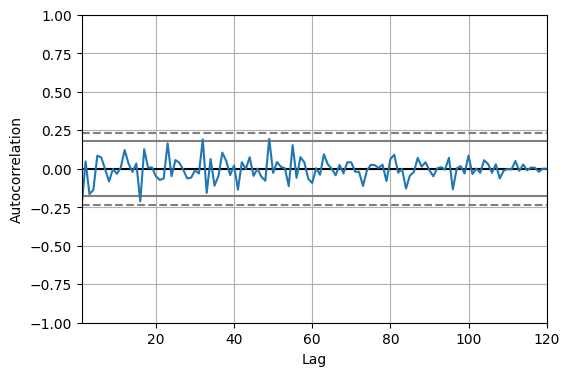

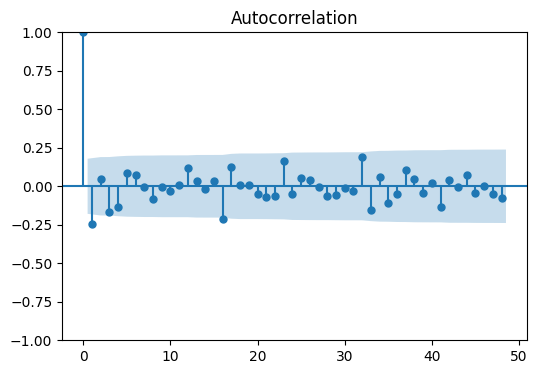

In [ ]:
from pandas.plotting import autocorrelation_plot

plt.clf()
autocorrelation_plot(hw_mul.resid)
plt.show()

plot_acf(hw_mul.resid, lags=48)
plt.show()

Y el aditivo?



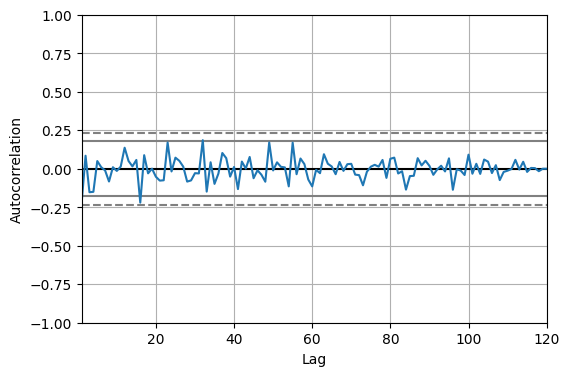

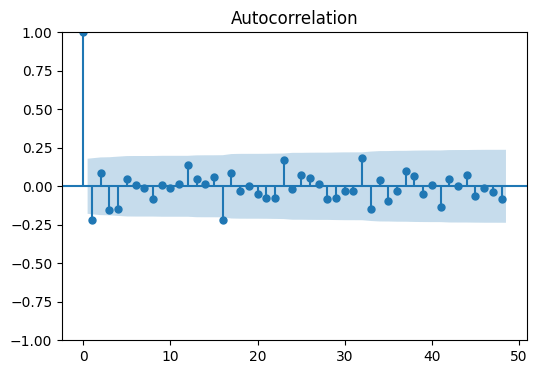

In [ ]:
plt.clf()
autocorrelation_plot(hw_add.resid)
plt.show()

plot_acf(hw_add.resid, lags=48)
plt.show()

# Series temporales II. Modelos ARIMA


## Definición de funciones para evaluación

Vamos a reciclar y adeuar las funciones necesarias para facilitarnos la vida en el proceso de ajuste de modelos (arima y en general).

La primera puede funcionar de forma general para cualquier modelo ya que su entrada es el vector de la serie residual..así podremos usarla para culquier filtro de series que apliquemos.

La segunda es una adecuación de la función definida en la parte de suavizado para que pueda funcionar sobre auto_arima (de otro paquete) pues tiene salidas y explotación de modelo distintas. En particular, en auto_arima el *forecast* es *predict* y *resid* es *resid()*


In [ ]:
import scipy.stats as stats
import seaborn as sns

# Función para evaluar residuos a través de contrastes de hipótesis
def residcheck(residuals, lags):
    """
    Function to check if the residuals are white noise. Ideally the residuals should be uncorrelated, zero mean,
    constant variance and normally distributed. First two are must, while last two are good to have.
    If the first two are not met, we have not fully captured the information from the data for prediction.
    Consider different model and/or add exogenous variable.

    If Ljung Box test shows p> 0.05, the residuals as a group are white noise. Some lags might still be significant.

    Lags should be min(2*seasonal_period, T/5)

    plots from: https://tomaugspurger.github.io/modern-7-timeseries.html

    """
    resid_mean = np.mean(residuals)
    lj_p_val = np.mean(sm.stats.acorr_ljungbox(x=residuals, lags=lags).lb_pvalue)
    norm_p_val =  stats.jarque_bera(residuals)[1]
    adfuller_p = adfuller(residuals)[1]


    fig = plt.figure(figsize=(10,8))
    layout = (2, 2)
    ts_ax = plt.subplot2grid(layout, (0, 0), colspan=2);
    acf_ax = plt.subplot2grid(layout, (1, 0));
    kde_ax = plt.subplot2grid(layout, (1, 1));

    residuals.plot(ax=ts_ax)
    plot_acf(residuals, lags=lags, ax=acf_ax);
    sns.kdeplot(residuals);
    #[ax.set_xlim(1.5) for ax in [acf_ax, kde_ax]]
    sns.despine()
    plt.tight_layout();
    plt.show()
    print("** Mean of the residuals: ", np.around(resid_mean,2))

    print("\n** Ljung Box Test, p-value:", np.around(lj_p_val,3),
        "(>0.05, Uncorrelated)" if (lj_p_val > 0.05) else "(<0.05, Correlated)")

    print("\n** Jarque Bera Normality Test, p_value:", np.around(norm_p_val,3),
        "(>0.05, Normal)" if (norm_p_val>0.05) else "(<0.05, Not-normal)")

    print("\n** AD Fuller, p_value:", np.around(adfuller_p,3),
        "(>0.05, Non-stationary)" if (adfuller_p > 0.05) else "(<0.05, Stationary)")

    return ts_ax, acf_ax, kde_ax




In [ ]:
# Función para evaluar modelo auto_arima
def eval_model_Aarima(model,tr,tst,name='Model',lags=12):
      lb = np.mean(sm.stats.acorr_ljungbox(model.resid(), lags=lags, return_df=True).lb_pvalue)
      pred = model.predict(n_periods=len(tst))
      fig1, ax = plt.subplots()
      ax.plot(tr, label='training')
      ax.plot(tst, label='test')
      ax.plot(pred, label='prediction')
      plt.legend(loc='upper left')
      tit = name + ":  LjungBox p-value --> " + str(lb) + "\n MAPE: " + str(round(mean_absolute_percentage_error(tst, pred)*100,2)) + "%"
      plt.title(tit)
      plt.ylabel('Serie')
      plt.xlabel('Date')
      plt.show()
      model.plot_diagnostics(figsize=(14,10))
      plt.show()


## Arima Manual

Podemos ajustar modelos ARIMA manuales con SARIMAX de statsmodels. Para ello, en primer lugar se deben evaluar las autodcoleraciones para identificar patrones de efectos AR y MA tentativos. Una vez tenemos una idea de los órdenes a proponer, ajustamos los modelos.

Recordamos correlogramas de la serie logaritmica y doblemente diferenciada.


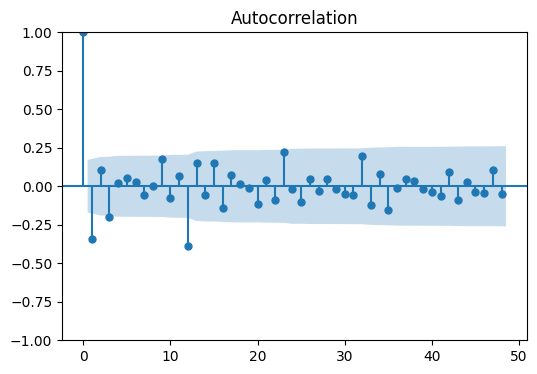

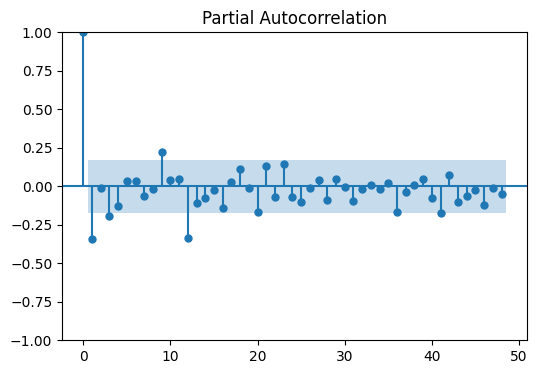

In [ ]:
plot_acf(AirLog_diff_1_12.dropna(inplace=False),lags=48)
plt.show()
plot_pacf(AirLog_diff_1_12.dropna(inplace=False),lags=48,method='ywm')
plt.show()


**ACF**: En lo regular, seguro que algo hay. Podría ser un AR si consideramos que hay decrecimiento rápido y no corte en el segundo retardo. Si es así, el órden del AR sería 1 por el corte en el pacf. En lo estacional, el retardo 12 es significativo así que algo debe haber.. No queda muy claro en si parte ar o ma..

**PACF**: Parece que hay un corte en el retardo 2, con lo que pensamos en AR, pero luego está ese retardo 3 con descenso..igual es un MA o un enmascaramiento de ambos. En lo estacional, de nuevo el retardo 12 jugando y no queda clara la dinámica de desaparición de las autocorrelaciones estacionales..

Con esto probaremos algo así como ARIMA(0-1,1,0-1)(0-1,1,0-1)[12]

**Modelo 1** -> Con ambas partes MA


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima1 = SARIMAX(Air_tr,
                order = (0, 1, 1),
                seasonal_order =(0, 1, 1, 12))

arima_1 = arima1.fit()
print(arima_1.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  120
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 197.505
Date:                            Sat, 13 Dec 2025   AIC                           -389.010
Time:                                    10:53:49   BIC                           -380.991
Sample:                                01-01-1949   HQIC                          -385.759
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.924      0.000      -0.514      -0.171
ma.S.L12      -0.5406      0.105   

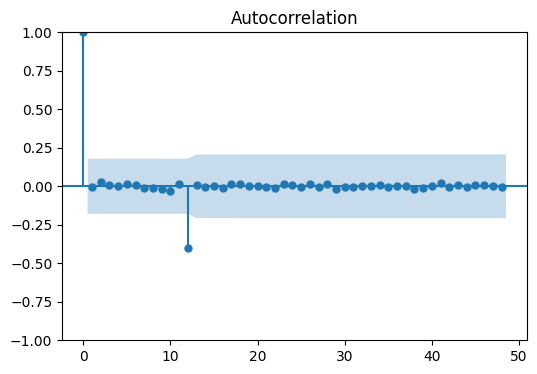

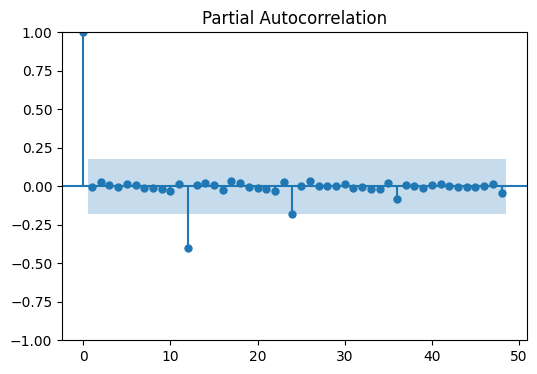

In [ ]:
plot_acf(arima_1.resid,lags=48)
plt.show()
plot_pacf(arima_1.resid,lags=48,method='ywm')
plt.show()


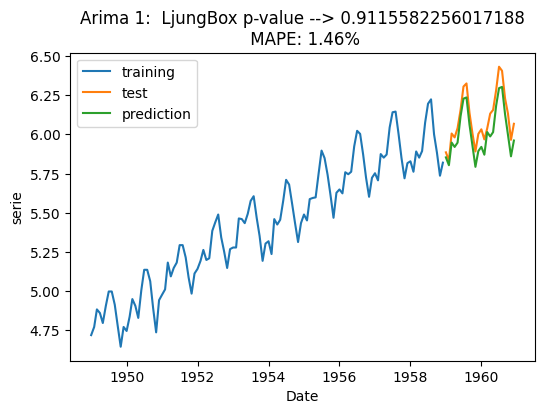

0.9115582256017188


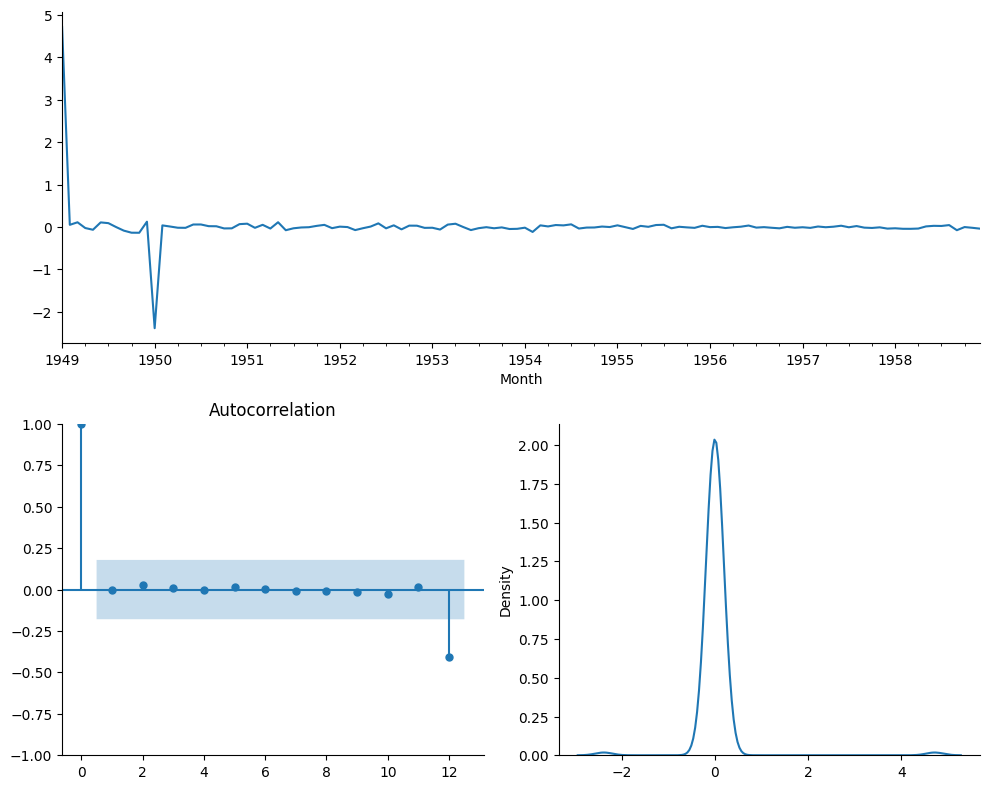

** Mean of the residuals:  0.02

** Ljung Box Test, p-value: 0.912 (>0.05, Uncorrelated)

** Jarque Bera Normality Test, p_value: 0.0 (<0.05, Not-normal)

** AD Fuller, p_value: 0.0 (<0.05, Stationary)


(<Axes: xlabel='Month'>,
 <Axes: title={'center': 'Autocorrelation'}>,
 <Axes: ylabel='Density'>)

In [ ]:
eval_model(arima_1,Air_tr,Air_tst,'Arima 1')

residcheck(arima_1.resid,12)


**Modelo 2** -> Con ambas partes AR



In [ ]:
arima2 = SARIMAX(Air_tr,
                order = (1, 1, 0),
                seasonal_order =(1, 1, 0, 12))

arima_2 = arima2.fit()
print(arima_2.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  120
Model:             SARIMAX(1, 1, 0)x(1, 1, 0, 12)   Log Likelihood                 194.679
Date:                            Sat, 13 Dec 2025   AIC                           -383.359
Time:                                    10:58:49   BIC                           -375.340
Sample:                                01-01-1949   HQIC                          -380.108
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3479      0.079     -4.403      0.000      -0.503      -0.193
ar.S.L12      -0.4427      0.076   

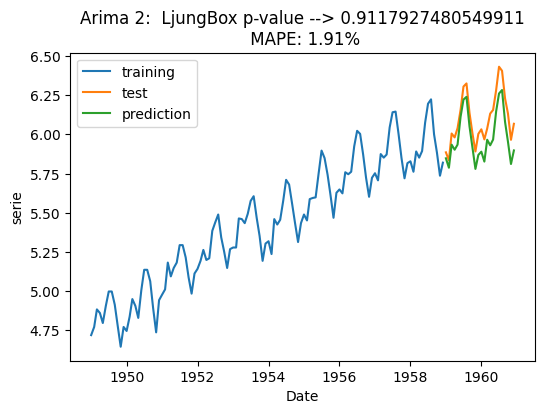

0.9117927480549911


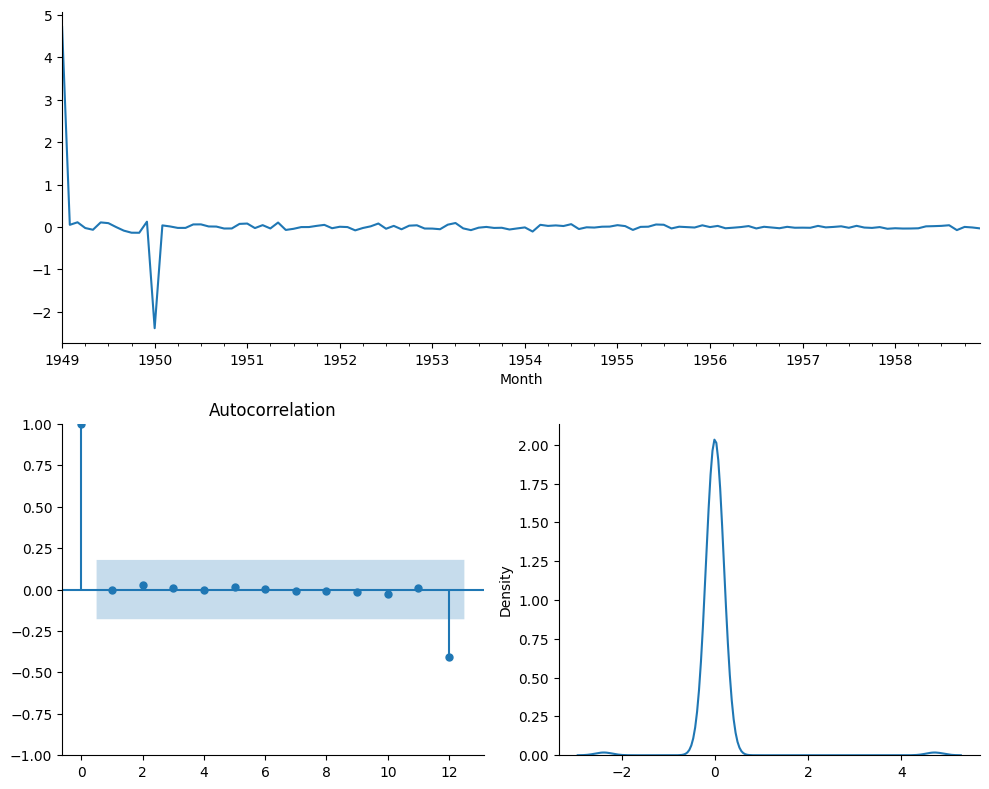

** Mean of the residuals:  0.02

** Ljung Box Test, p-value: 0.912 (>0.05, Uncorrelated)

** Jarque Bera Normality Test, p_value: 0.0 (<0.05, Not-normal)

** AD Fuller, p_value: 0.0 (<0.05, Stationary)


(<Axes: xlabel='Month'>,
 <Axes: title={'center': 'Autocorrelation'}>,
 <Axes: ylabel='Density'>)

In [ ]:
eval_model(arima_2,Air_tr,Air_tst,'Arima 2')

residcheck(arima_2.resid,12)


**Modelo 3** -> Superposición de efectos ARMA en regular y estacional



In [ ]:
arima3 = SARIMAX(Air_tr,
                order = (0, 1, 1),
                seasonal_order =(1, 0, 1, 12))

arima_3 = arima3.fit()
print(arima_3.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  120
Model:             SARIMAX(0, 1, 1)x(1, 0, 1, 12)   Log Likelihood                 202.731
Date:                            Sat, 13 Dec 2025   AIC                           -397.463
Time:                                    11:16:05   BIC                           -386.346
Sample:                                01-01-1949   HQIC                          -392.949
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2776      0.080     -3.477      0.001      -0.434      -0.121
ar.S.L12       0.9983      0.002   

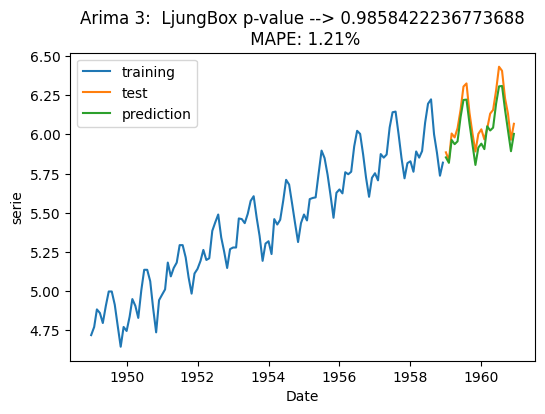

0.9858422236773688


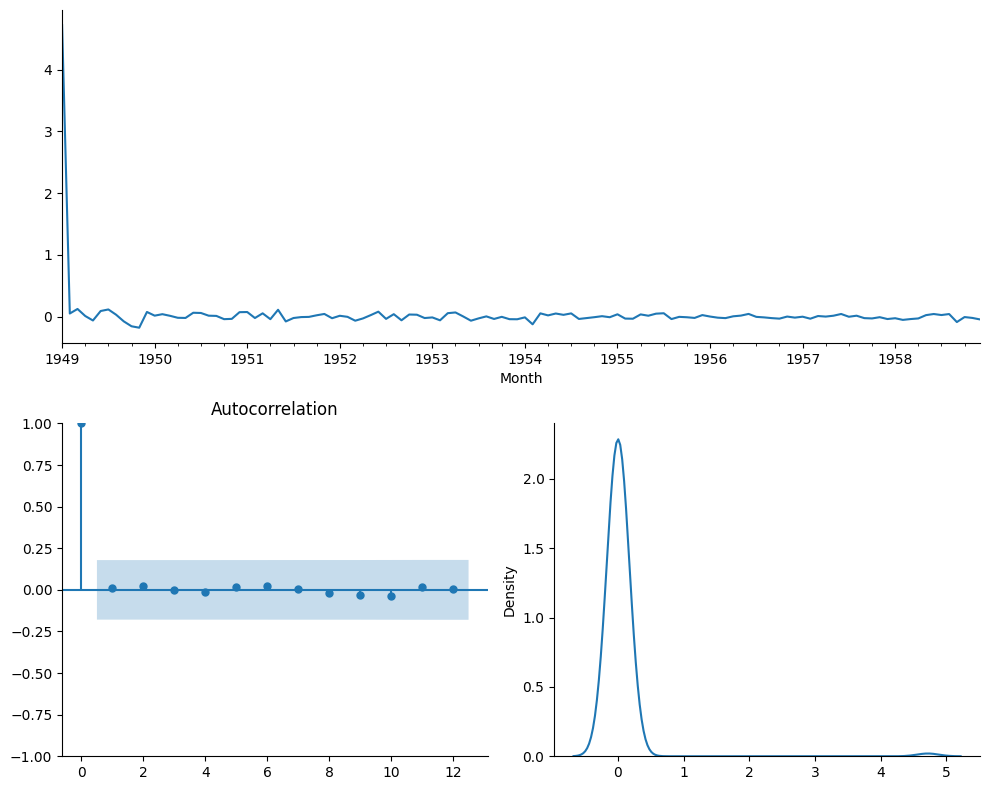

** Mean of the residuals:  0.04

** Ljung Box Test, p-value: 0.986 (>0.05, Uncorrelated)

** Jarque Bera Normality Test, p_value: 0.0 (<0.05, Not-normal)

** AD Fuller, p_value: 0.0 (<0.05, Stationary)


(<Axes: xlabel='Month'>,
 <Axes: title={'center': 'Autocorrelation'}>,
 <Axes: ylabel='Density'>)

In [ ]:
eval_model(arima_3,Air_tr,Air_tst,'Arima 3')
residcheck(arima_3.resid,12)


## Arima automático

En esta parte presentamos la selección de modelos arima mediante AIC que implementa el paquete *pmdarima*. Se puede jugar bastante con órdenes máximos y mínimos para los efectos autoregresivos y de medias móviles, así como con las diferenciaciones regular y estacional.


Vamos a ajustar el mejor modelo ARIMA automático a la serie clásica de vuelos.


In [ ]:
#!pip install pmdarima
import pmdarima as pm

# Ajustamos modelo arima step-wise con métrica AIC para la serie de vuelos
arima_auto = pm.auto_arima(Air_tr, start_p=1, start_q=1,
                      test='adf',       # use adftest to find optimal 'd'
                      max_p=3, max_q=3, # maximum p and q
                      m=12,              # frequency of series
                      d=1,           # let model determine 'd'
                      seasonal=True,   # No Seasonality
                      #start_P=None,
                      D=0,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True,
                      stepwise=True)

print(arima_auto.summary())


Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,1)[12] intercept   : AIC=-389.673, Time=2.13 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=-193.784, Time=0.05 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=inf, Time=0.74 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=-272.605, Time=0.53 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=-194.869, Time=0.07 sec
 ARIMA(1,1,1)(0,0,1)[12] intercept   : AIC=-270.701, Time=0.78 sec
 ARIMA(1,1,1)(1,0,0)[12] intercept   : AIC=-379.294, Time=4.90 sec
 ARIMA(1,1,1)(2,0,1)[12] intercept   : AIC=-397.876, Time=4.38 sec
 ARIMA(1,1,1)(2,0,0)[12] intercept   : AIC=-396.853, Time=3.06 sec
 ARIMA(1,1,1)(2,0,2)[12] intercept   : AIC=inf, Time=7.92 sec
 ARIMA(1,1,1)(1,0,2)[12] intercept   : AIC=-399.117, Time=3.14 sec
 ARIMA(1,1,1)(0,0,2)[12] intercept   : AIC=-304.018, Time=1.50 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=-401.023, Time=1.54 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=-305.012, Time=0.76 sec
 ARIMA(0,1,1)(1,0,1)[12] inte

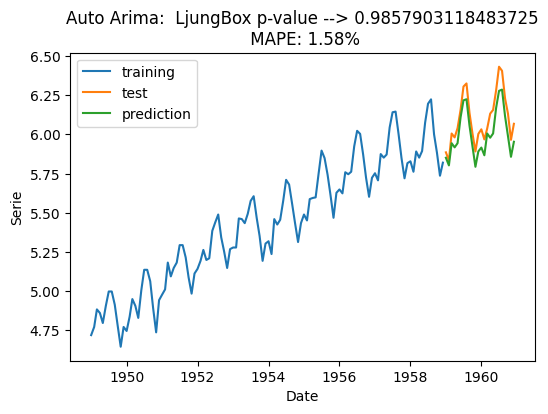

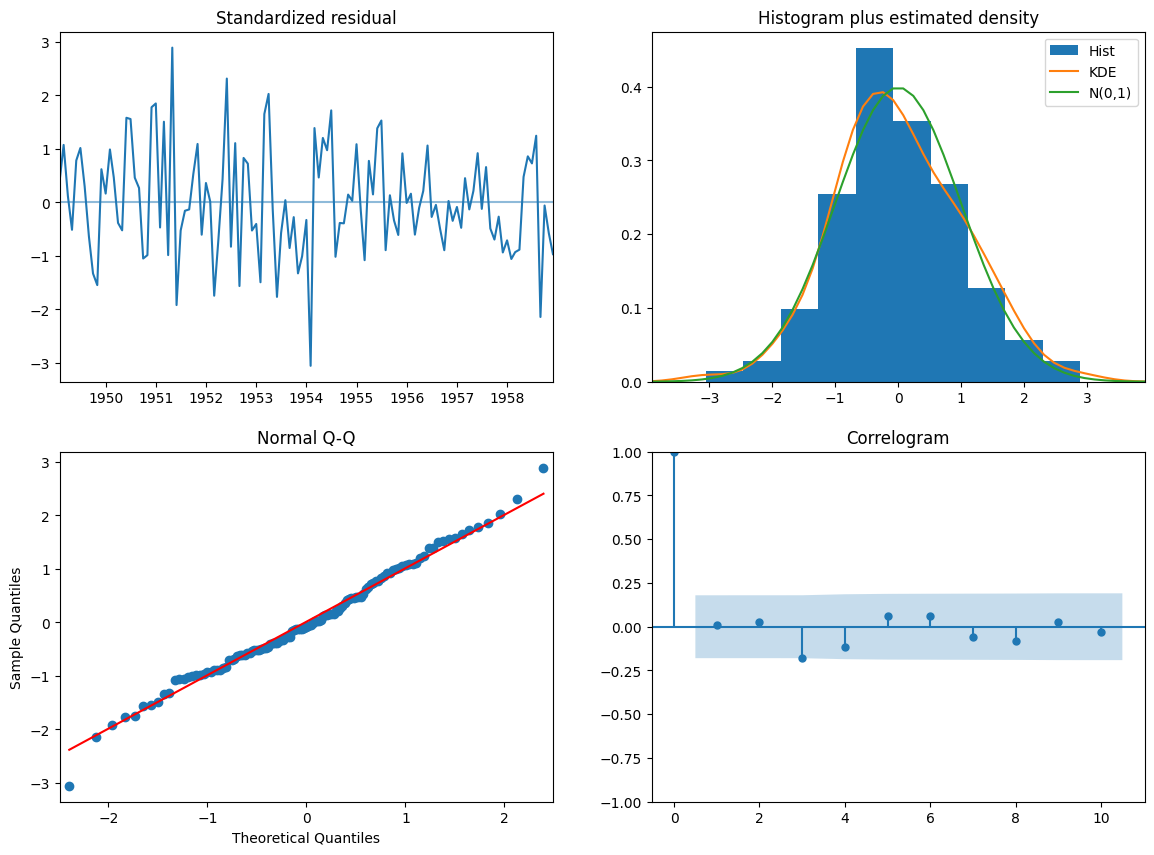

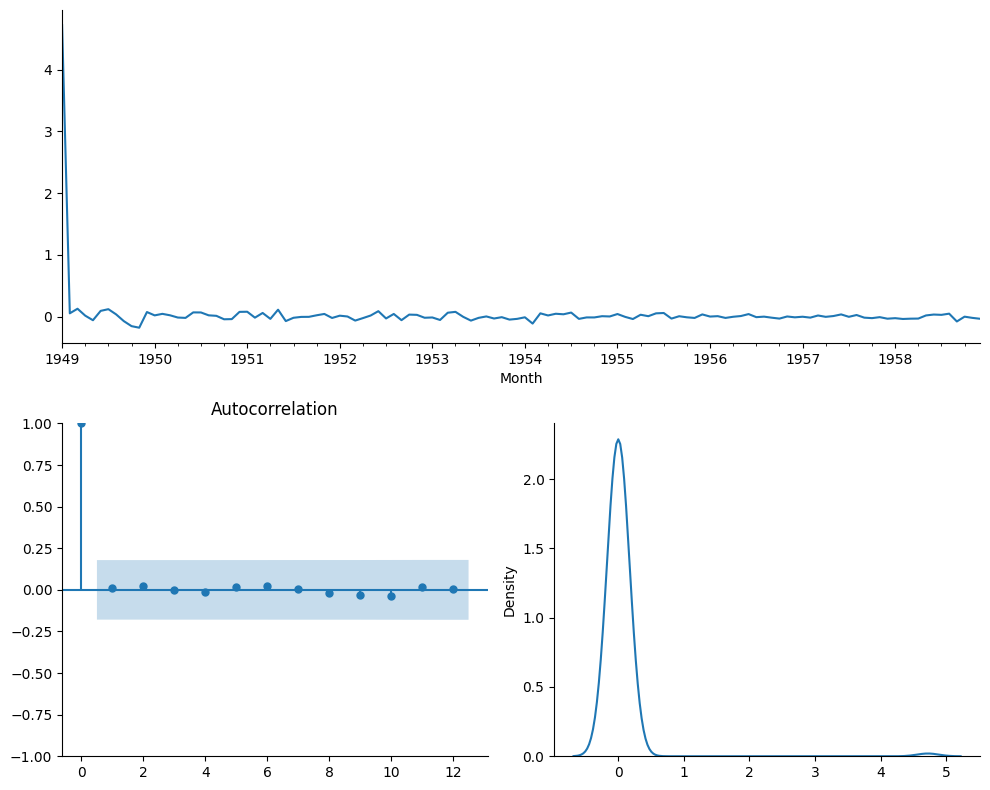

** Mean of the residuals:  0.04

** Ljung Box Test, p-value: 0.986 (>0.05, Uncorrelated)

** Jarque Bera Normality Test, p_value: 0.0 (<0.05, Not-normal)

** AD Fuller, p_value: 0.0 (<0.05, Stationary)


(<Axes: xlabel='Month'>,
 <Axes: title={'center': 'Autocorrelation'}>,
 <Axes: ylabel='Density'>)

In [ ]:
eval_model_Aarima(arima_auto,Air_tr,Air_tst,'Auto Arima')
residcheck(arima_auto.resid(),12)


# Aplicación a Datos sobre viajeros en la ciudad de córdoba

Ejemplo Cordoba (datos Cordoba.xlsx), donde trataremos de explorar los mejores modelos de suavizado y arima para las dos series que contiene.


In [ ]:
# pip install openpyxl
#Lectura de datos
Cordoba = pd.read_excel('/content/drive/MyDrive/Material Minería de Datos 2025_26 Gr2/Datos/Cordoba.xlsx')
Cordoba.head()


,,V_Resident,V_Extranj
0,2005M01,27816,9332
1,2005M02,34920,11387
2,2005M03,45221,21663
3,2005M04,41027,29094
4,2005M05,50750,32076


Cambiamos la M típica del INE por un guion para generar la fecha correctamente.



In [ ]:
Cordoba['Month'] = Cordoba.iloc[:,0].apply(lambda x: x.replace('M','-'))



In [ ]:
Cordoba

,,V_Resident,V_Extranj,Month
0,2005M01,27816,9332,2005-01
1,2005M02,34920,11387,2005-02
2,2005M03,45221,21663,2005-03
3,2005M04,41027,29094,2005-04
4,2005M05,50750,32076,2005-05
...,...,...,...,...
171,2019M04,45505,52570,2019-04
172,2019M05,50118,54483,2019-05
173,2019M06,41135,42241,2019-06
174,2019M07,36156,33851,2019-07


In [ ]:
Cordoba = Cordoba.iloc[:,1:]
Cordoba.head()


,V_Resident,V_Extranj,Month
0,27816,9332,2005-01
1,34920,11387,2005-02
2,45221,21663,2005-03
3,41027,29094,2005-04
4,50750,32076,2005-05


Convertir a serie temporal con la fecha indexada.



In [ ]:
Cordoba.set_index(['Month'],inplace=True)
Cordoba.index=pd.to_datetime(Cordoba.index)


Veamos.



In [ ]:
Cordoba.head()



,V_Resident,V_Extranj
Month,,
2005-01-01,27816,9332
2005-02-01,34920,11387
2005-03-01,45221,21663
2005-04-01,41027,29094
2005-05-01,50750,32076


Tenemos la serie de viajeros residentes y la de viajeros extranjeros. Nos preguntamos si se comportan igual en cuanto al turismo en Córdoba.



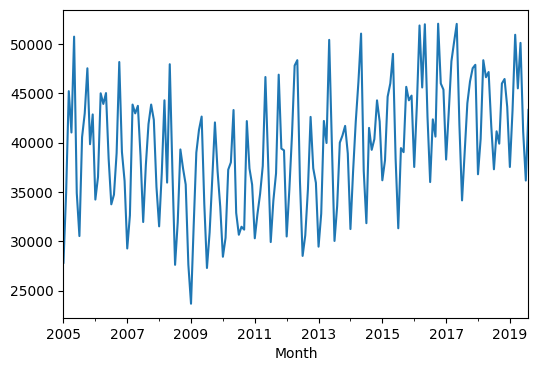

In [ ]:
Cordoba.V_Resident.plot()
plt.show()


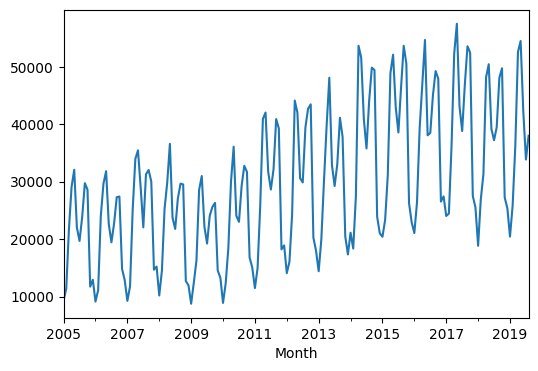

In [ ]:
Cordoba.V_Extranj.plot()
plt.show()


Evaluar la estacionariedad de las series al natural.



In [ ]:
test_stationarity(Cordoba.V_Extranj)
test_stationarity(Cordoba.V_Resident)


Results of Dickey-Fuller Test:
Test Statistic                  -2.121733
p-value                          0.533907
#Lags Used                      14.000000
Number of Observations Used    161.000000
Critical Value (1%)             -4.016129
Critical Value (5%)             -3.438119
Critical Value (10%)            -3.143266
dtype: float64
Results of Dickey-Fuller Test:
Test Statistic                  -2.200183
p-value                          0.489748
#Lags Used                      12.000000
Number of Observations Used    163.000000
Critical Value (1%)             -4.015411
Critical Value (5%)             -3.437776
Critical Value (10%)            -3.143065
dtype: float64


**Descomposición multiplicativa**



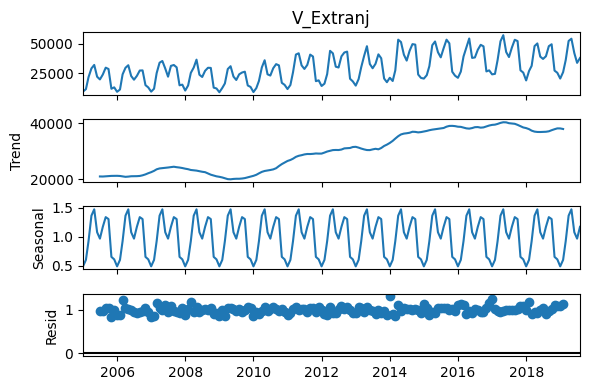

In [ ]:
# Aplicar descomposición aditiva
result_E = seasonal_decompose(Cordoba.V_Extranj, model='multiplicative',period=12)
result_E.plot()
plt.show()


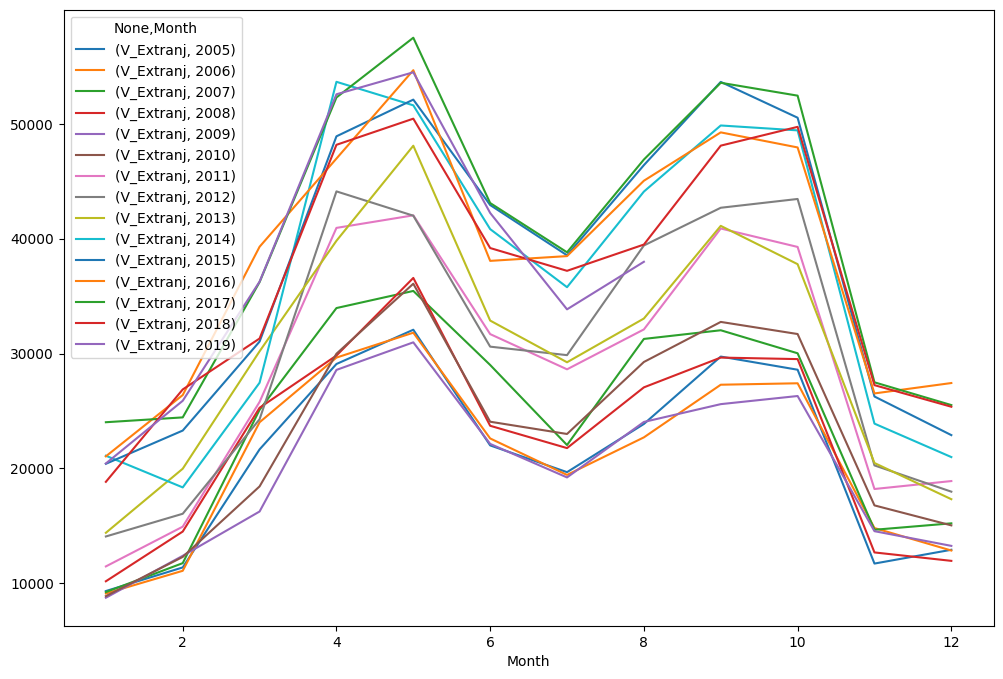

Results of Dickey-Fuller Test:
Test Statistic                -7.290593e+00
p-value                        3.081450e-09
#Lags Used                     9.000000e+00
Number of Observations Used    1.540000e+02
Critical Value (1%)           -4.018792e+00
Critical Value (5%)           -3.439393e+00
Critical Value (10%)          -3.144011e+00
dtype: float64


In [ ]:
# Gráfico de estacionalidad
seasonal_plot(Cordoba,column='V_Extranj')
plt.show()

# Test de estacionariedad para los residuos
test_stationarity(result_E.resid.dropna())


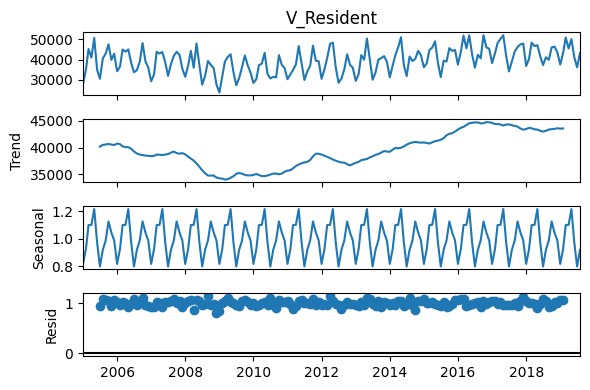

In [ ]:
# Aplicar descomposición aditiva
result_R = seasonal_decompose(Cordoba.V_Resident, model='multiplicative',period=12)
result_R.plot()
plt.show()


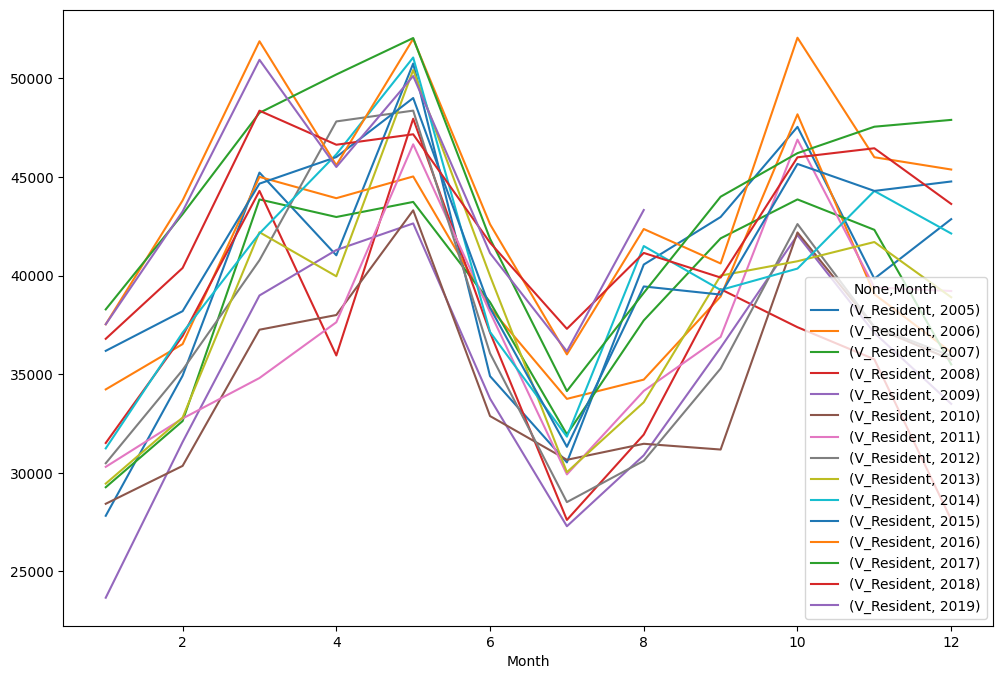

Results of Dickey-Fuller Test:
Test Statistic                -7.386349e+00
p-value                        1.859340e-09
#Lags Used                     9.000000e+00
Number of Observations Used    1.540000e+02
Critical Value (1%)           -4.018792e+00
Critical Value (5%)           -3.439393e+00
Critical Value (10%)          -3.144011e+00
dtype: float64


In [ ]:
# Gráfico de estacionalidad
seasonal_plot(Cordoba)
plt.show()

# Test de estacionariedad para los residuos
test_stationarity(result_R.resid.dropna())


Gráficos de aurocorrelación de residuos con bandas de confianza.



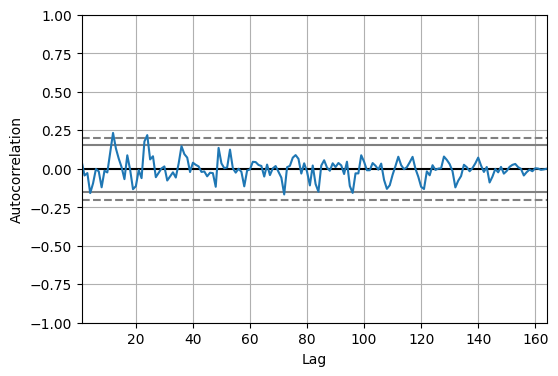

In [ ]:
autocorrelation_plot(result_E.resid.dropna())
plt.show()



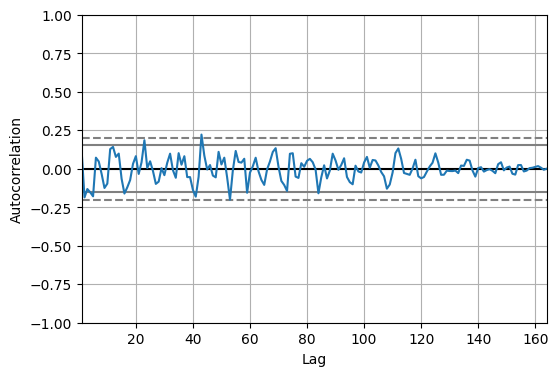

In [ ]:
autocorrelation_plot(result_R.resid.dropna())
plt.show()

Contraste de Ljung-Box para residuos de la descomposición multiplicativa



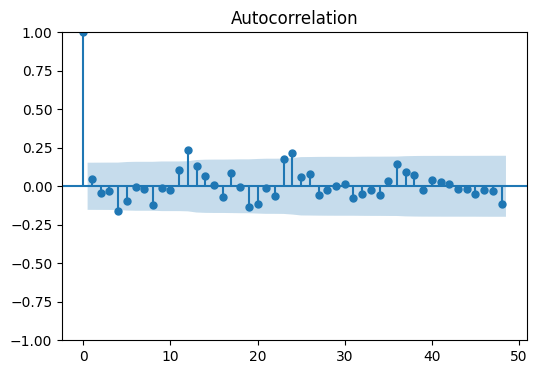

In [ ]:
plot_acf(result_E.resid.dropna(),lags=48)
plt.show()

In [ ]:
sm.stats.acorr_ljungbox(result_E.resid.dropna(), lags=12, return_df=True)


,lb_stat,lb_pvalue
1,0.390086,0.532254
2,0.715787,0.699147
3,0.851541,0.837103
4,5.112490,0.275949
5,6.650613,0.247948
6,6.651175,0.354314
7,6.705458,0.460178
8,9.249181,0.321714
9,9.280102,0.411830
10,9.381525,0.496318


In [ ]:
sm.stats.acorr_ljungbox(result_R.resid.dropna(), lags=12, return_df=True)


,lb_stat,lb_pvalue
1,2.237791,0.134673
2,8.071325,0.017674
3,11.011894,0.011662
4,14.998395,0.004705
5,20.502372,0.001005
6,21.391819,0.001560
7,21.768829,0.002784
8,21.966624,0.004978
9,24.710894,0.003308
10,26.363710,0.003281


**Partición training-test**



In [ ]:
Cordoba_tr = Cordoba[:'2017-12-01']
Cordoba_tst = Cordoba['2018-01-01':]


## Modelos de Suavizado

En esta sección vamos a ajustar modelos de suavizado que parezcar realistas para estas series. Es evidente que nada de simple y doble y nos vamos a Holt Winters. Vamos a probar aditivo y multiplicativo para ambas series.

1. **Extranjeros**

Modelo aditivo.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


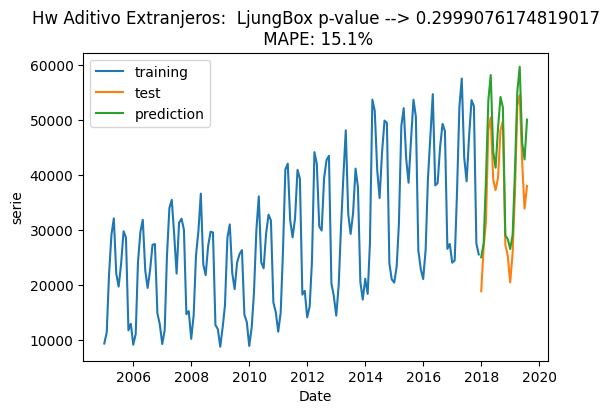

0.2999076174819017


In [ ]:
hw_add = ets.ExponentialSmoothing(Cordoba_tr.V_Extranj,trend='add', damped_trend=False, seasonal='add').fit()
eval_model(hw_add,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Hw Aditivo Extranjeros')


Modelo multiplicativo.



/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


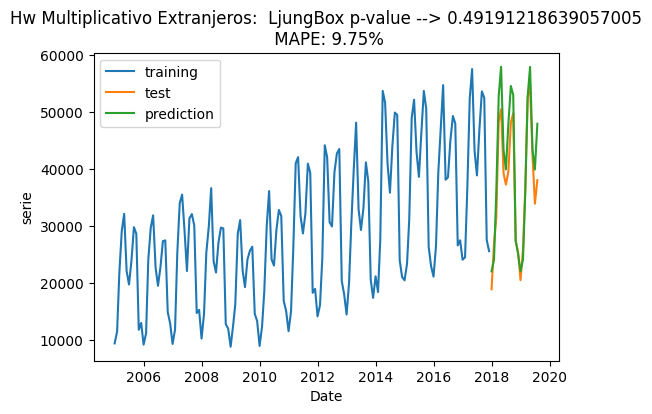

0.49191218639057005


In [ ]:
hw_mul = ets.ExponentialSmoothing(Cordoba_tr.V_Extranj,trend='add', damped_trend=False, seasonal='mul').fit()
eval_model(hw_mul,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Hw Multiplicativo Extranjeros')


2. **Residentes**

Modelo aditivo.


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


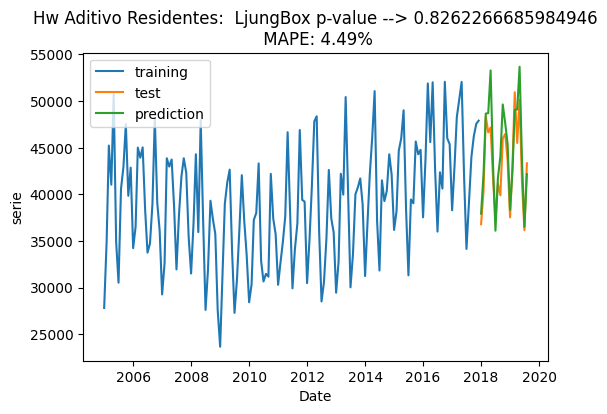

0.8262266685984946


In [ ]:
hw_add = ets.ExponentialSmoothing(Cordoba_tr.V_Resident,trend='add', damped_trend=False, seasonal='add').fit()
eval_model(hw_add,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Hw Aditivo Residentes')


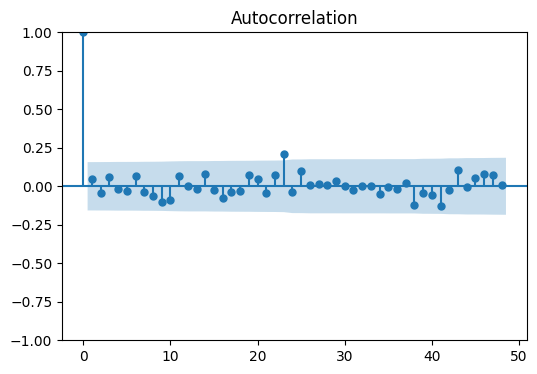

In [ ]:

plot_acf(hw_add.resid.dropna(inplace=False),lags=48)
plt.show()

Modelo multiplicativo.



/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


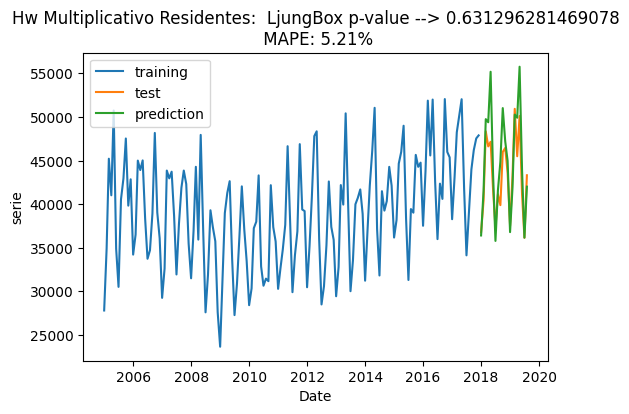

0.631296281469078


In [ ]:
hw_mul = ets.ExponentialSmoothing(Cordoba_tr.V_Resident,trend='add', damped_trend=False, seasonal='mul').fit()
eval_model(hw_mul,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Hw Multiplicativo Residentes')


## Modelos ARIMA

1. **Extranjeros**

Vistazo a correlogramas.


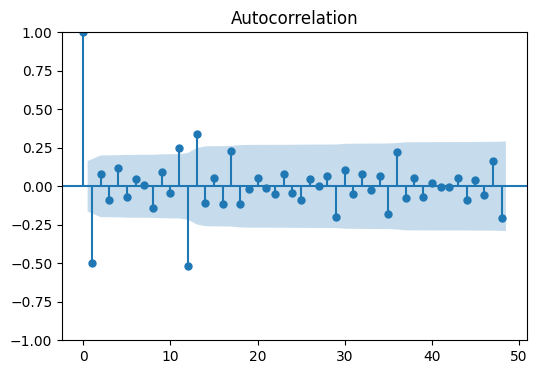

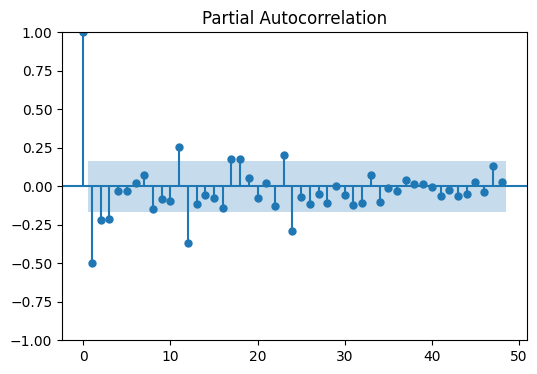

In [ ]:
Extranj_diff_1_12 = Cordoba_tr.V_Extranj.diff(periods=1).diff(periods=12)

plot_acf(Extranj_diff_1_12.dropna(inplace=False),lags=48)
plt.show()
plot_pacf(Extranj_diff_1_12.dropna(inplace=False),lags=48,method='ywm')
plt.show()


ACF que se corta en retardo 1, parece Ma 1 en lo regular. También hay corte en retardo 12, huele a MA 1 estacional.
PACF confirma un poco las sospechas, podríamos decir decrecimiento geométrico en lo regular pero podría haber bajada desde el retardo 1 por lo que podría enmascarar un AR 1.. En lo estacional, decrecimiento, parece MA.

Asi pues, podemos proponer algo como ARIMA(0-1,1,1)(0,1,1)[12] y jugar un poco por ahí.


**Arima Manual**


In [ ]:
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima1 = SARIMAX(Cordoba_tr.V_Extranj,
                order = (0, 1, 1),
                seasonal_order =(0, 1, 1, 12))

arima_1 = arima1.fit()
arima_1.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                          V_Extranj   No. Observations:                  156
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -1348.235
Date:                            Sat, 13 Dec 2025   AIC                           2702.470
Time:                                    11:39:28   BIC                           2711.359
Sample:                                01-01-2005   HQIC                          2706.082
                                     - 12-01-2017                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5649      0.058     -9.741      0.000      -0.679      -0.451
ma.S.L12      -0.4795      0.065     -7.352      0.000      -0.607      -0.352
sigma2      8.663e+06   7.82e+05     11.085      0.000    7.13e+06    1.02e+07
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                17.18
Prob(Q):                              0.89   Prob(JB):                         0.00
Heteroskedasticity (H):               1.54   Skew:                             0.40
Prob(H) (two-sided):                  0.14   Kurtosis:                         4.50
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

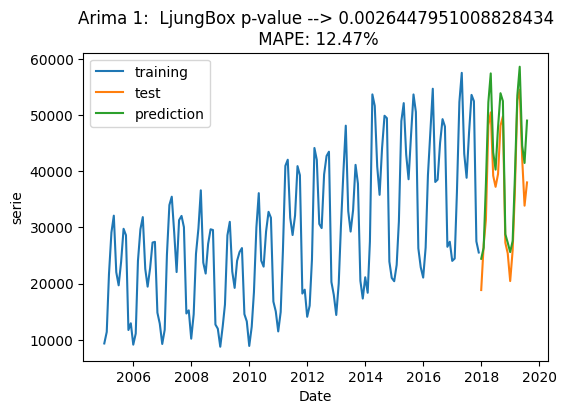

0.0026447951008828434


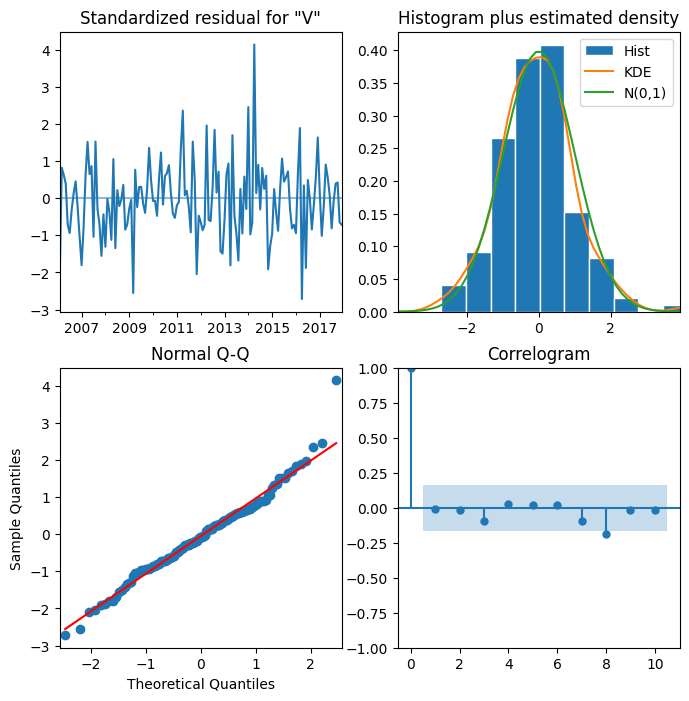

In [ ]:
eval_model(arima_1,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Arima 1')
arima_1.plot_diagnostics(figsize=(8,8))
plt.show()

In [ ]:
arima2 = SARIMAX(Cordoba_tr.V_Extranj,
                order = (1, 1, 1),
                seasonal_order =(0, 1, 1, 12))

arima_2 = arima2.fit()
arima_2.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                          V_Extranj   No. Observations:                  156
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -1348.099
Date:                            Sat, 13 Dec 2025   AIC                           2704.197
Time:                                    11:41:38   BIC                           2716.049
Sample:                                01-01-2005   HQIC                          2709.013
                                     - 12-01-2017                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0793      0.158      0.503      0.615      -0.230       0.389
ma.L1         -0.6163      0.119     -5.182      0.000      -0.849      -0.383
ma.S.L12      -0.4903      0.068     -7.202      0.000      -0.624      -0.357
sigma2      8.643e+06   7.85e+05     11.013      0.000    7.11e+06    1.02e+07
===================================================================================
Ljung-Box (L1) (Q):                   0.20   Jarque-Bera (JB):                18.82
Prob(Q):                              0.66   Prob(JB):                         0.00
Heteroskedasticity (H):               1.52   Skew:                             0.40
Prob(H) (two-sided):                  0.15   Kurtosis:                         4.58
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

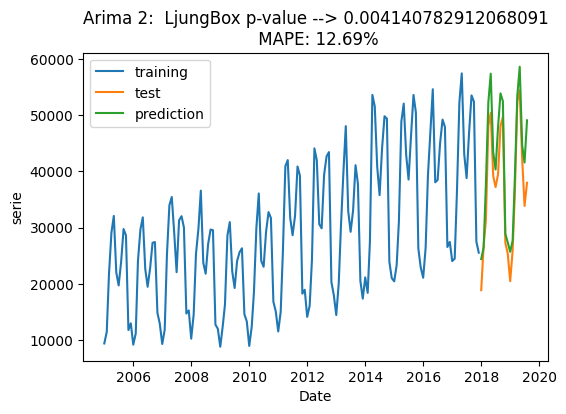

0.004140782912068091


In [ ]:
eval_model(arima_2,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Arima 2')



Probamos adiferenciar de orden 2 en lo regular.



In [ ]:
arima3 = SARIMAX(Cordoba_tr.V_Extranj,
                order = (1, 2, 2),
                seasonal_order =(0, 1, 1, 12))

arima_3 = arima3.fit()
arima_3.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                            V_Extranj   No. Observations:                  156
Model:             SARIMAX(1, 2, 2)x(0, 1, [1], 12)   Log Likelihood               -1350.884
Date:                              Sat, 13 Dec 2025   AIC                           2711.768
Time:                                      11:50:36   BIC                           2726.547
Sample:                                  01-01-2005   HQIC                          2717.774
                                       - 12-01-2017                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1357      0.198      0.686      0.493      -0.252       0.523
ma.L1         -1.5512      0.195     -7.941      0.000      -1.934      -1.168
ma.L2          0.5522      0.189      2.920      0.004       0.182       0.923
ma.S.L12      -0.5297      0.076     -6.930      0.000      -0.680      -0.380
sigma2      1.005e+07   2.34e-08    4.3e+14      0.000    1.01e+07    1.01e+07
===================================================================================
Ljung-Box (L1) (Q):                   0.54   Jarque-Bera (JB):                10.86
Prob(Q):                              0.46   Prob(JB):                         0.00
Heteroskedasticity (H):               1.02   Skew:                             0.33
Prob(H) (two-sided):                  0.94   Kurtosis:                         4.19
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 6.21e+30. Standard errors may be unstable.
"""

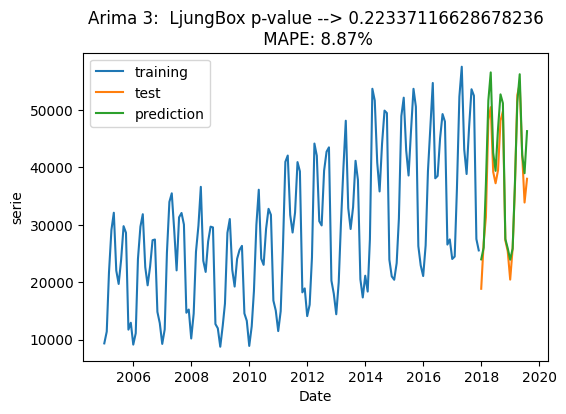

0.22337116628678236


In [ ]:
eval_model(arima_3,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Arima 3')



Auto ARIMA

Vamos a aplicar automatismos para buscar los mejores órdenes en relación al AIC utilizando auro_arima.


In [ ]:
# Auto arima
arima_auto = pm.auto_arima(Cordoba_tr.V_Extranj, start_p=1, start_q=1,
                      test='adf',       # use adftest to find optimal 'd'
                      max_p=3, max_q=3, # maximum p and q
                      m=12,              # frequency of series
                      d=2,           # let model determine 'd'
                      seasonal=True,   # No Seasonality
                      #start_P=None,
                      D=None,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True,
                      stepwise=True)

print(arima_auto.summary())


Performing stepwise search to minimize aic
 ARIMA(1,2,1)(1,1,1)[12]             : AIC=inf, Time=6.90 sec
 ARIMA(0,2,0)(0,1,0)[12]             : AIC=2924.228, Time=0.14 sec
 ARIMA(1,2,0)(1,1,0)[12]             : AIC=2807.137, Time=1.24 sec
 ARIMA(0,2,1)(0,1,1)[12]             : AIC=inf, Time=3.34 sec
 ARIMA(1,2,0)(0,1,0)[12]             : AIC=2837.587, Time=0.32 sec
 ARIMA(1,2,0)(2,1,0)[12]             : AIC=2799.067, Time=1.42 sec
 ARIMA(1,2,0)(2,1,1)[12]             : AIC=2800.645, Time=2.48 sec
 ARIMA(1,2,0)(1,1,1)[12]             : AIC=2794.444, Time=2.11 sec
 ARIMA(1,2,0)(0,1,1)[12]             : AIC=2799.773, Time=1.66 sec
 ARIMA(1,2,0)(1,1,2)[12]             : AIC=inf, Time=8.45 sec
 ARIMA(1,2,0)(0,1,2)[12]             : AIC=2793.990, Time=4.82 sec
 ARIMA(0,2,0)(0,1,2)[12]             : AIC=2859.093, Time=5.01 sec
 ARIMA(2,2,0)(0,1,2)[12]             : AIC=2770.998, Time=4.46 sec
 ARIMA(2,2,0)(0,1,1)[12]             : AIC=2775.698, Time=0.37 sec
 ARIMA(2,2,0)(1,1,2)[12]          

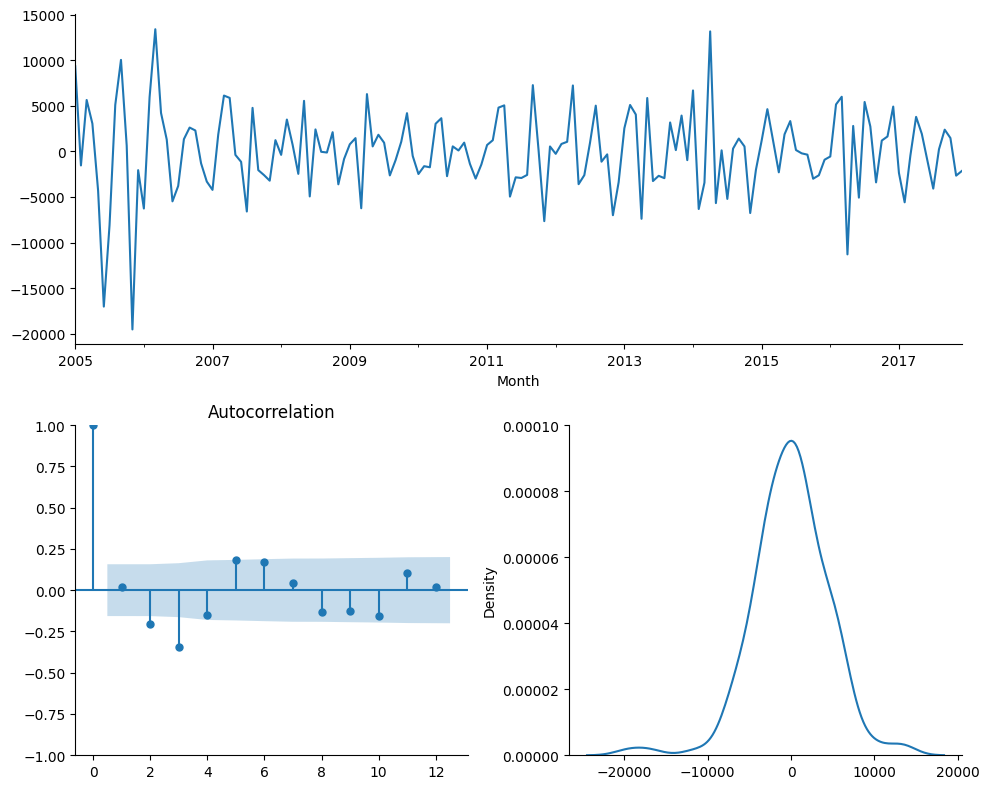

** Mean of the residuals:  -35.67

** Ljung Box Test, p-value: 0.068 (>0.05, Uncorrelated)

** Jarque Bera Normality Test, p_value: 0.0 (<0.05, Not-normal)

** AD Fuller, p_value: 0.0 (<0.05, Stationary)


(<Axes: xlabel='Month'>,
 <Axes: title={'center': 'Autocorrelation'}>,
 <Axes: ylabel='Density'>)

In [ ]:
residcheck(arima_auto.resid(),12)



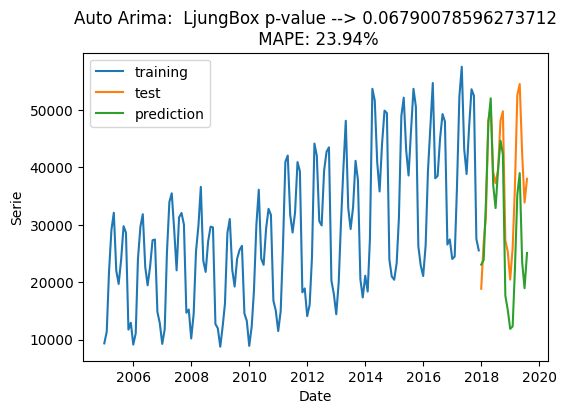

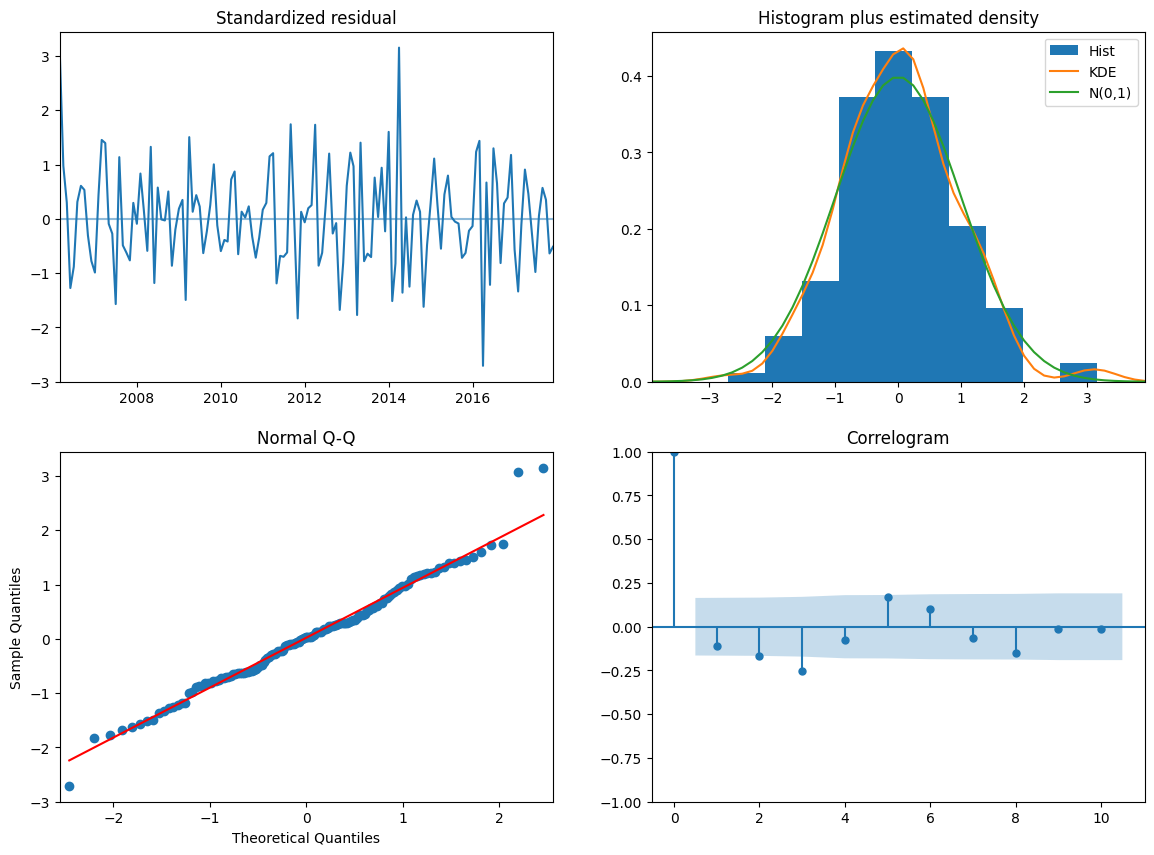

In [ ]:
eval_model_Aarima(arima_auto,Cordoba_tr.V_Extranj,Cordoba_tst.V_Extranj,'Auto Arima')



2. **Residentes**

Vistazo a correlogramas.


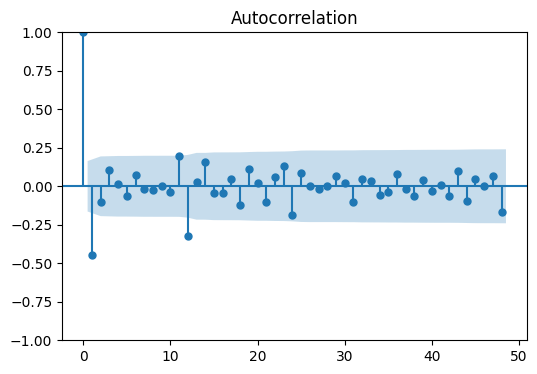

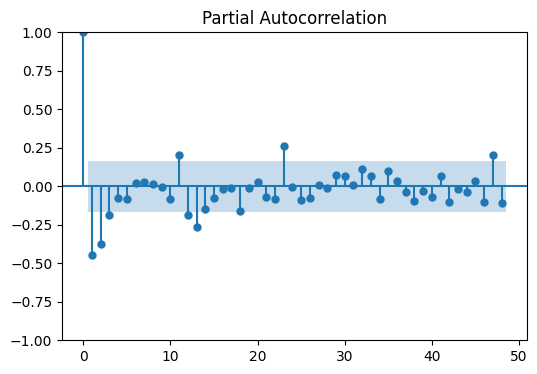

In [ ]:
Resid_diff_1= Cordoba_tr.V_Resident.diff(periods=1)#.diff(periods=12)

plot_acf(Resid_diff_1.diff(periods=12).dropna(inplace=False),lags=48)
plt.show()
plot_pacf(Resid_diff_1.diff(periods=12).dropna(inplace=False),lags=48,method='ywm')
plt.show()


Parte AR de orden 2 enmascarada por parte MA de orden 1 en lo regular.

Parte AR de orden 1-2 enmascarada por algo de MA seguramente en lo estacional

Por esto nuestros candidatos a ajustar serían: ARIMA(2,1,1)(1-2,1,0-1-2)[12], o cualquiera de sus variaciones en las porsiciones autoregresivas o de medias móviles.

**Arima Manual**


In [ ]:
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima1 = SARIMAX(Cordoba_tr.V_Resident,
                order = (0, 1, 2),
                seasonal_order =(0, 1, 1, 12))

arima_1 = arima1.fit()
arima_1.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                           V_Resident   No. Observations:                  156
Model:             SARIMAX(0, 1, 2)x(0, 1, [1], 12)   Log Likelihood               -1365.740
Date:                              Sat, 13 Dec 2025   AIC                           2739.480
Time:                                      11:54:59   BIC                           2751.332
Sample:                                  01-01-2005   HQIC                          2744.296
                                       - 12-01-2017                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3084      0.046     -6.758      0.000      -0.398      -0.219
ma.L2         -0.0772      0.089     -0.864      0.388      -0.252       0.098
ma.S.L12      -0.6169      0.062     -9.953      0.000      -0.738      -0.495
sigma2      1.156e+07   8.32e-10   1.39e+16      0.000    1.16e+07    1.16e+07
===================================================================================
Ljung-Box (L1) (Q):                   3.01   Jarque-Bera (JB):                 2.14
Prob(Q):                              0.08   Prob(JB):                         0.34
Heteroskedasticity (H):               0.50   Skew:                            -0.22
Prob(H) (two-sided):                  0.02   Kurtosis:                         3.41
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

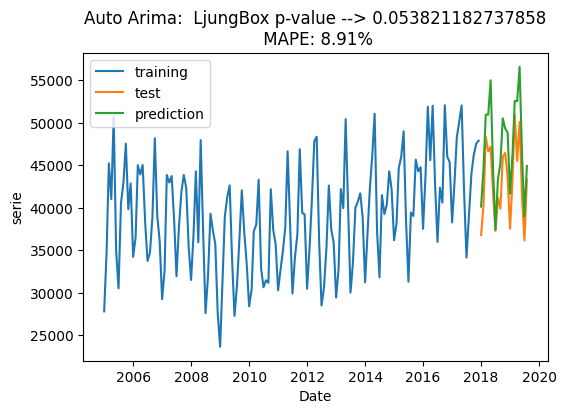

0.053821182737858


In [ ]:
eval_model(arima_1,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Auto Arima')



In [ ]:
arima2 = SARIMAX(Cordoba_tr.V_Resident,
                order = (0, 1, 1),
                seasonal_order =(2, 0, 1, 12))

arima_2 = arima2.fit()
arima_2.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                         V_Resident   No. Observations:                  156
Model:             SARIMAX(0, 1, 1)x(2, 0, 1, 12)   Log Likelihood               -1513.725
Date:                            Sat, 13 Dec 2025   AIC                           3037.450
Time:                                    11:56:37   BIC                           3052.667
Sample:                                01-01-2005   HQIC                          3043.631
                                     - 12-01-2017                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5673      0.039    -14.626      0.000      -0.643      -0.491
ar.S.L12       1.1138      0.057     19.556      0.000       1.002       1.225
ar.S.L24      -0.1142      0.057     -2.015      0.044      -0.225      -0.003
ma.S.L12      -0.9718      0.090    -10.855      0.000      -1.147      -0.796
sigma2      1.487e+07   5.65e-09   2.63e+15      0.000    1.49e+07    1.49e+07
===================================================================================
Ljung-Box (L1) (Q):                   2.83   Jarque-Bera (JB):                30.66
Prob(Q):                              0.09   Prob(JB):                         0.00
Heteroskedasticity (H):               0.27   Skew:                             0.23
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.13
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.09e+30. Standard errors may be unstable.
"""

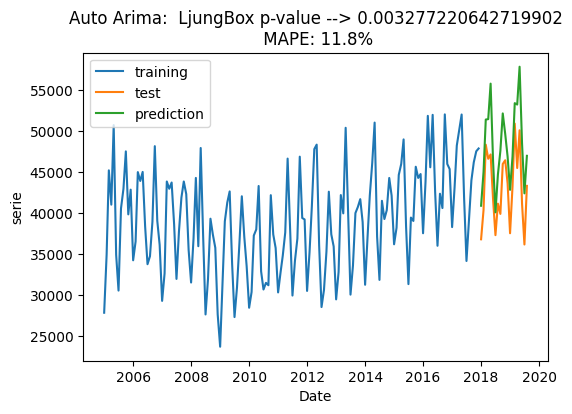

0.003277220642719902


In [ ]:
eval_model(arima_2,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Auto Arima')



In [ ]:
sm.stats.acorr_ljungbox(arima_2.resid.dropna(), lags=12, return_df=True)

,lb_stat,lb_pvalue
1,4.776154,0.028857
2,5.996332,0.049878
3,6.226136,0.101112
4,6.454726,0.167665
5,8.982099,0.109780
6,10.512834,0.104651
7,16.433446,0.021438
8,16.434450,0.036567
9,16.846207,0.051180
10,21.124533,0.020242


In [ ]:
arima3 = SARIMAX(Cordoba_tr.V_Resident,
                order = (0, 1, 1),
                seasonal_order =(1, 0, 1 ,12))

arima_3 = arima3.fit()
arima_3.summary()


C:\Users\Guille\anaconda3\envs\Mineria\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Guille\anaconda3\envs\Mineria\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                         V_Resident   No. Observations:                  156
Model:             SARIMAX(0, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1511.087
Date:                           mi., 11 dic. 2024   AIC                           3030.175
Time:                                    14:40:43   BIC                           3042.349
Sample:                                01-01-2005   HQIC                          3035.120
                                     - 12-01-2017                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5129      0.040    -12.892      0.000      -0.591      -0.435
ar.S.L12       0.9732      0.018     53.125      0.000       0.937       1.009
ma.S.L12      -0.7487      0.079     -9.495      0.000      -0.903      -0.594
sigma2      1.535e+07   3.48e-09   4.41e+15      0.000    1.53e+07    1.53e+07
===================================================================================
Ljung-Box (L1) (Q):                   1.27   Jarque-Bera (JB):                47.31
Prob(Q):                              0.26   Prob(JB):                         0.00
Heteroskedasticity (H):               0.24   Skew:                            -0.15
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.69
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 1.8e+30. Standard errors may be unstable.
"""

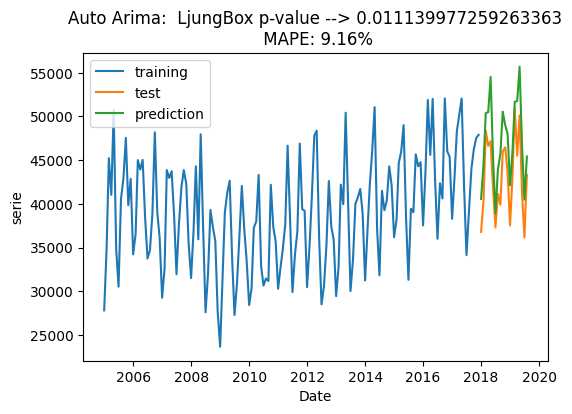

0.011139977259263363


In [ ]:
eval_model(arima_3,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Auto Arima')



Auto ARIMA

Vamos a aplicar automatismos para buscar los mejores órdenes en relación al AIC utilizando auro_arima.


In [ ]:
Cordoba_tr.V_Resident.shape

(156,)

In [ ]:
# Auto arima
arima_auto = pm.auto_arima(Cordoba_tr.V_Resident, start_p=1, start_q=1,
                      test='adf',       # use adftest to find optimal 'd'
                      max_p=5, max_q=5, # maximum p and q
                      m=12,              # frequency of series
                      d=2,           # let model determine 'd'
                      seasonal=True,   # No Seasonality
                      #start_P=None,
                      D=2,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True,
                      stepwise=True)

print(arima_auto.summary())


Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,1)[12] intercept   : AIC=inf, Time=1.16 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=3156.226, Time=0.03 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=3065.344, Time=0.32 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=3109.121, Time=0.95 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=3154.295, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=3158.127, Time=0.04 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=3056.735, Time=1.01 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=3066.765, Time=1.03 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=3037.652, Time=0.73 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=3099.284, Time=0.34 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=3069.929, Time=1.71 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=3107.161, Time=0.43 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=2.23 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=inf, Time=2.01 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

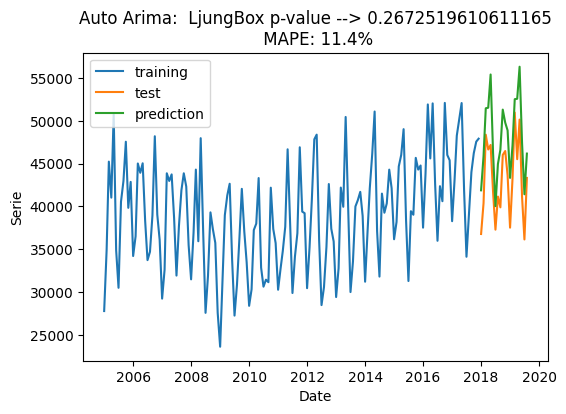

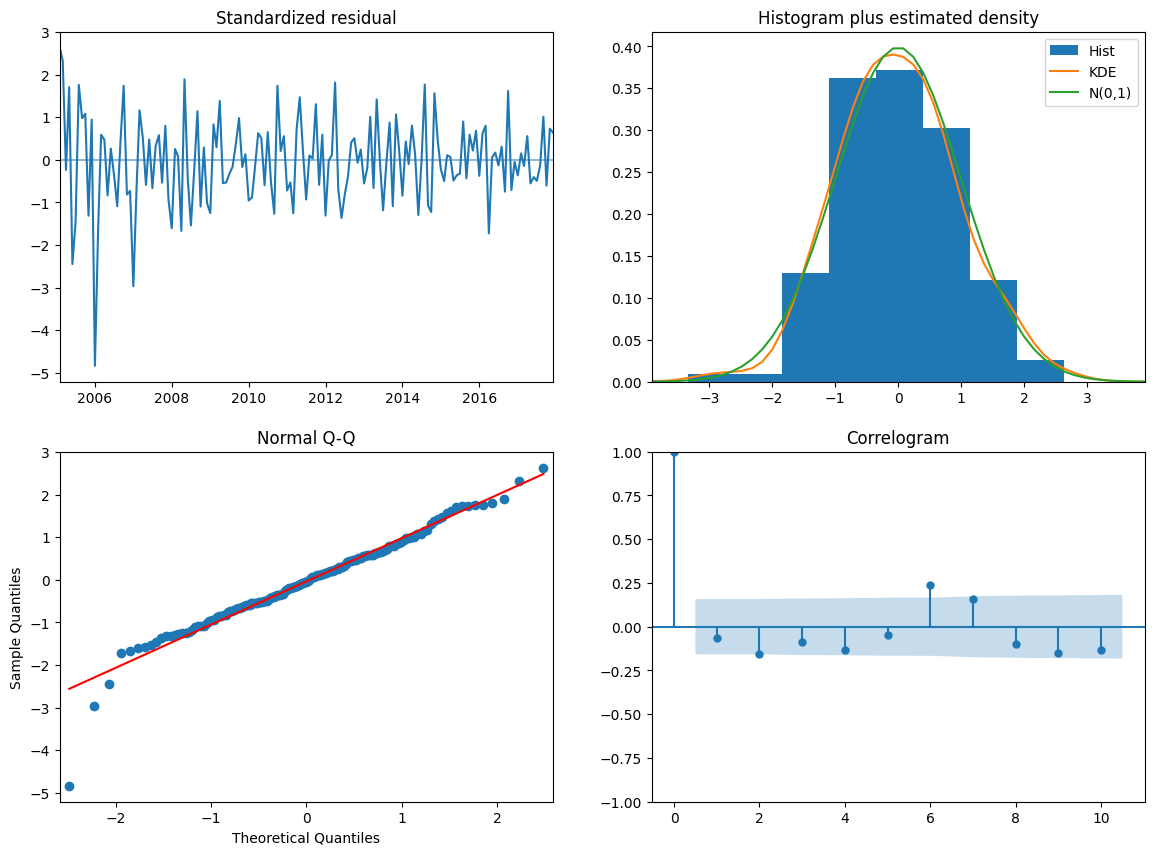

In [ ]:
#residcheck(arima_auto.resid(),12)
eval_model_Aarima(arima_auto,Cordoba_tr.V_Resident,Cordoba_tst.V_Resident,'Auto Arima')


In [ ]:
sm.stats.acorr_ljungbox(arima_auto.resid(), lags=12, return_df=True)

,lb_stat,lb_pvalue
1,0.649617,0.420250
2,0.694962,0.706465
3,1.824129,0.609698
4,2.333949,0.674595
5,5.180260,0.394280
6,8.166206,0.226178
7,16.595781,0.020197
8,16.891344,0.031261
9,17.794068,0.037639
10,21.428622,0.018295


In [ ]:
arima_auto.resid()

Month
2005-01-01    28145.998738
2005-02-01    14071.149323
2005-03-01    12441.825154
2005-04-01    -1274.369995
2005-05-01     9111.599497
                  ...     
2017-08-01     -559.894133
2017-09-01     4056.665006
2017-10-01    -2426.646380
2017-11-01     2935.069583
2017-12-01     2578.822670
Length: 156, dtype: float64